In [36]:
import pandas as pd
df = pd.read_csv("HR_Employee_Attrition.csv")

In [37]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [38]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [39]:
round(df.describe(),2)

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.00,1470.00,1470.00,1470.00,1470.0,1470.00,1470.00,1470.00,1470.00,1470.00,...,1470.00,1470.0,1470.00,1470.00,1470.00,1470.00,1470.00,1470.00,1470.00,1470.00
mean,36.92,802.49,9.19,2.91,1.0,1024.87,2.72,65.89,2.73,2.06,...,2.71,80.0,0.79,11.28,2.80,2.76,7.01,4.23,2.19,4.12
std,9.14,403.51,8.11,1.02,0.0,602.02,1.09,20.33,0.71,1.11,...,1.08,0.0,0.85,7.78,1.29,0.71,6.13,3.62,3.22,3.57
min,18.00,102.00,1.00,1.00,1.0,1.00,1.00,30.00,1.00,1.00,...,1.00,80.0,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00
25%,30.00,465.00,2.00,2.00,1.0,491.25,2.00,48.00,2.00,1.00,...,2.00,80.0,0.00,6.00,2.00,2.00,3.00,2.00,0.00,2.00
50%,36.00,802.00,7.00,3.00,1.0,1020.50,3.00,66.00,3.00,2.00,...,3.00,80.0,1.00,10.00,3.00,3.00,5.00,3.00,1.00,3.00
75%,43.00,1157.00,14.00,4.00,1.0,1555.75,4.00,83.75,3.00,3.00,...,4.00,80.0,1.00,15.00,3.00,3.00,9.00,7.00,3.00,7.00
max,60.00,1499.00,29.00,5.00,1.0,2068.00,4.00,100.00,4.00,5.00,...,4.00,80.0,3.00,40.00,6.00,4.00,40.00,18.00,15.00,17.00


In [40]:
df.nunique()

Age                           43
Attrition                      2
BusinessTravel                 3
DailyRate                    886
Department                     3
DistanceFromHome              29
Education                      5
EducationField                 6
EmployeeCount                  1
EmployeeNumber              1470
EnvironmentSatisfaction        4
Gender                         2
HourlyRate                    71
JobInvolvement                 4
JobLevel                       5
JobRole                        9
JobSatisfaction                4
MaritalStatus                  3
MonthlyIncome               1349
MonthlyRate                 1427
NumCompaniesWorked            10
Over18                         1
OverTime                       2
PercentSalaryHike             15
PerformanceRating              2
RelationshipSatisfaction       4
StandardHours                  1
StockOptionLevel               4
TotalWorkingYears             40
TrainingTimesLastYear          7
WorkLifeBa

We notice that 'EmployeeCount', 'Over18', 'StandardHours' have only one unique values and 'EmployeeNumber' has 1470 unique values. This features aren't useful for us, So we are going to drop those columns

In [41]:
df.drop(['EmployeeCount','Over18','StandardHours'], axis=1, inplace=True)

**📉 Categorical Features:**

In [42]:
object_col = []

for column in df.columns:
    if df[column].dtype in ['object', 'string'] and df[column].nunique() <= 30:
        object_col.append(column)
        
        print(f"{column} : {df[column].unique()}\n")
        print(df[column].value_counts())
        print("+-----------------------------------")

if 'Attrition' in object_col:
    object_col.remove('Attrition')


Attrition : <ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str

Attrition
No     1233
Yes     237
Name: count, dtype: int64
+-----------------------------------
BusinessTravel : <ArrowStringArray>
['Travel_Rarely', 'Travel_Frequently', 'Non-Travel']
Length: 3, dtype: str

BusinessTravel
Travel_Rarely        1043
Travel_Frequently     277
Non-Travel            150
Name: count, dtype: int64
+-----------------------------------
Department : <ArrowStringArray>
['Sales', 'Research & Development', 'Human Resources']
Length: 3, dtype: str

Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64
+-----------------------------------
EducationField : <ArrowStringArray>
[   'Life Sciences',            'Other',          'Medical',
        'Marketing', 'Technical Degree',  'Human Resources']
Length: 6, dtype: str

EducationField
Life Sciences       606
Medical             464
Marketing           159
Technical Degree    132
O

In [43]:
len(object_col)

7

In [44]:
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder

label = LabelEncoder()
df["Attrition"] = label.fit_transform(df.Attrition)

In [45]:
df["Attrition"]

0       1
1       0
2       1
3       0
4       0
       ..
1465    0
1466    0
1467    0
1468    0
1469    0
Name: Attrition, Length: 1470, dtype: int64

**📉 Numerical Features:**

In [46]:
object_col = []

for column in df.columns:
    if df[column].dtype not in ['object', 'string'] and df[column].nunique() <= 30:
        object_col.append(column)
        
        print(f"{column} : {df[column].unique()}")
        print("+------------------------------------")

if 'Attrition' in object_col:
    object_col.remove('Attrition')


Attrition : [1 0]
+------------------------------------
DistanceFromHome : [ 1  8  2  3 24 23 27 16 15 26 19 21  5 11  9  7  6 10  4 25 12 18 29 22
 14 20 28 17 13]
+------------------------------------
Education : [2 1 4 3 5]
+------------------------------------
EnvironmentSatisfaction : [2 3 4 1]
+------------------------------------
JobInvolvement : [3 2 4 1]
+------------------------------------
JobLevel : [2 1 3 4 5]
+------------------------------------
JobSatisfaction : [4 2 3 1]
+------------------------------------
NumCompaniesWorked : [8 1 6 9 0 4 5 2 7 3]
+------------------------------------
PercentSalaryHike : [11 23 15 12 13 20 22 21 17 14 16 18 19 24 25]
+------------------------------------
PerformanceRating : [3 4]
+------------------------------------
RelationshipSatisfaction : [1 4 2 3]
+------------------------------------
StockOptionLevel : [0 1 3 2]
+------------------------------------
TrainingTimesLastYear : [0 3 2 5 1 4 6]
+------------------------------------

In [47]:
cont_col = []
for column in df.columns:
    if df[column].dtypes not in ['object', 'string'] and df[column].nunique() > 30:
        print(f"{column} : Minimum: {df[column].min()}, Maximum: {df[column].max()}")
        cont_col.append(column)
        print("---")

Age : Minimum: 18, Maximum: 60
---
DailyRate : Minimum: 102, Maximum: 1499
---
EmployeeNumber : Minimum: 1, Maximum: 2068
---
HourlyRate : Minimum: 30, Maximum: 100
---
MonthlyIncome : Minimum: 1009, Maximum: 19999
---
MonthlyRate : Minimum: 2094, Maximum: 26999
---
TotalWorkingYears : Minimum: 0, Maximum: 40
---
YearsAtCompany : Minimum: 0, Maximum: 40
---


#### **📉 Data Visualisation:**

In [48]:
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

<Axes: xlabel='DistanceFromHome', ylabel='Count'>

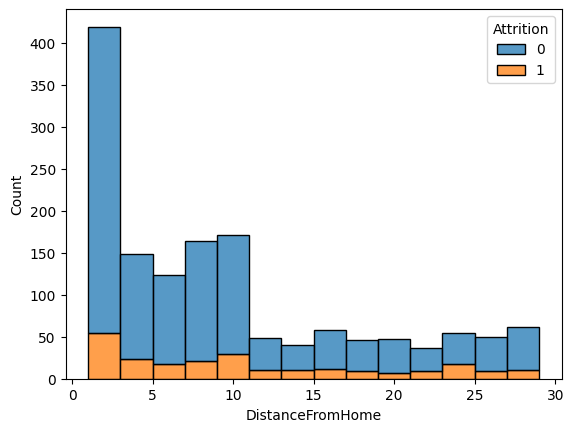

In [49]:
sns.histplot(data=df,x='DistanceFromHome',hue='Attrition',multiple="stack",)

<Axes: xlabel='Education', ylabel='Count'>

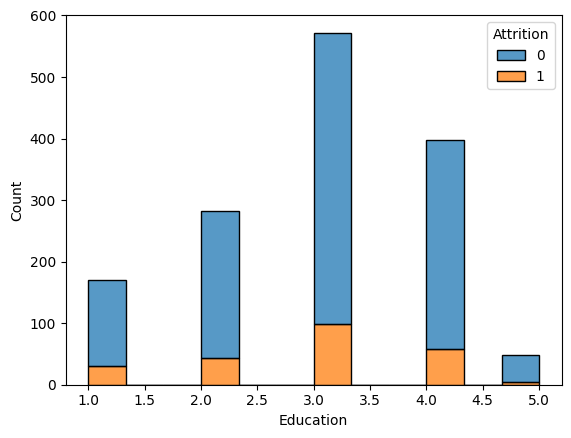

In [50]:
sns.histplot(data=df,x='Education',hue='Attrition',multiple="stack",)

<Axes: xlabel='RelationshipSatisfaction', ylabel='Count'>

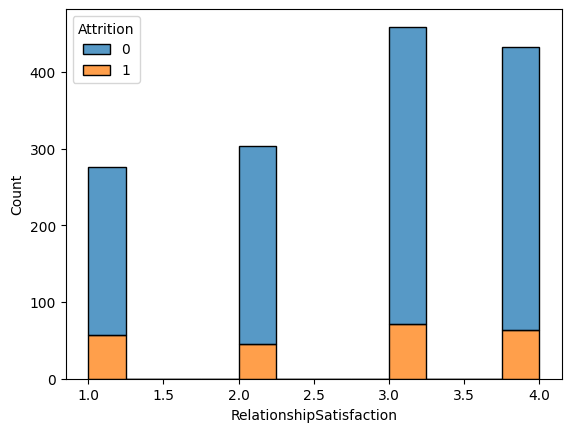

In [51]:
sns.histplot(data=df,x='RelationshipSatisfaction',hue='Attrition',multiple="stack",)

<Axes: xlabel='EnvironmentSatisfaction', ylabel='Count'>

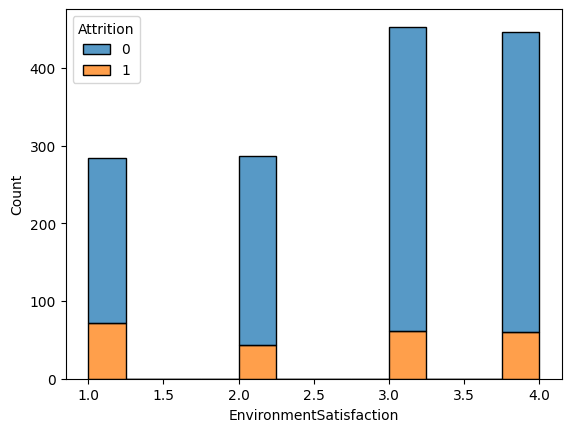

In [52]:
sns.histplot(data=df,x='EnvironmentSatisfaction',hue='Attrition',multiple="stack",)

<Axes: xlabel='JobInvolvement', ylabel='Count'>

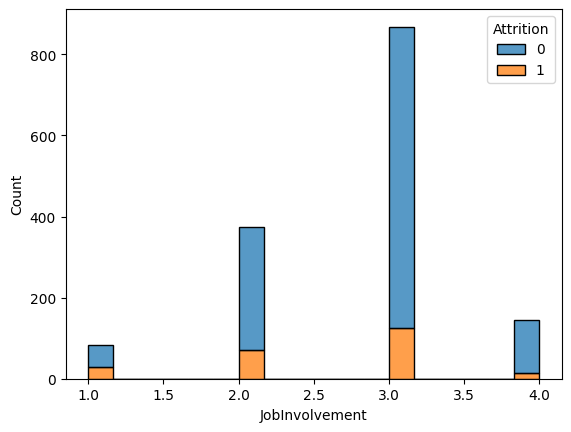

In [53]:
sns.histplot(data=df,x='JobInvolvement',hue='Attrition',multiple="stack",)

<Axes: xlabel='JobLevel', ylabel='Count'>

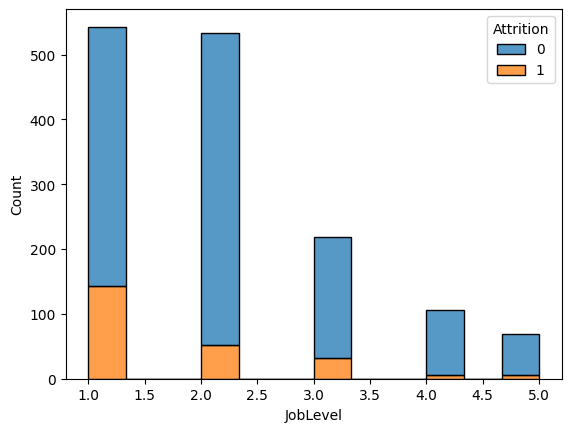

In [54]:
sns.histplot(data=df,x='JobLevel',hue='Attrition',multiple="stack",)

<Axes: xlabel='JobSatisfaction', ylabel='Count'>

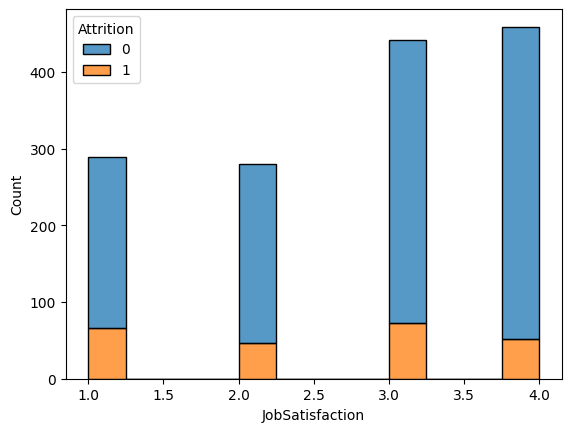

In [55]:
sns.histplot(data=df,x='JobSatisfaction',hue='Attrition',multiple="stack",)

<Axes: xlabel='NumCompaniesWorked', ylabel='Count'>

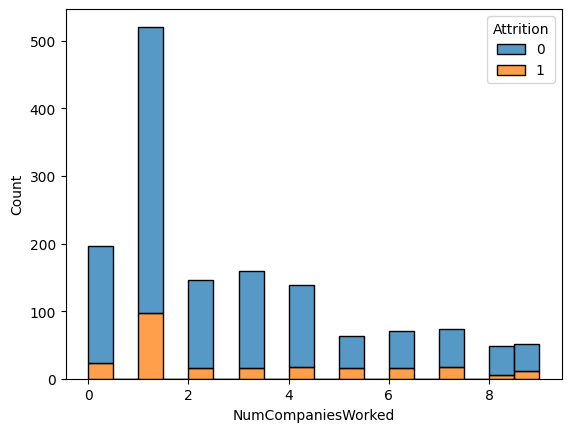

In [56]:
sns.histplot(data=df,x='NumCompaniesWorked',hue='Attrition',multiple="stack",)

<Axes: xlabel='PercentSalaryHike', ylabel='Count'>

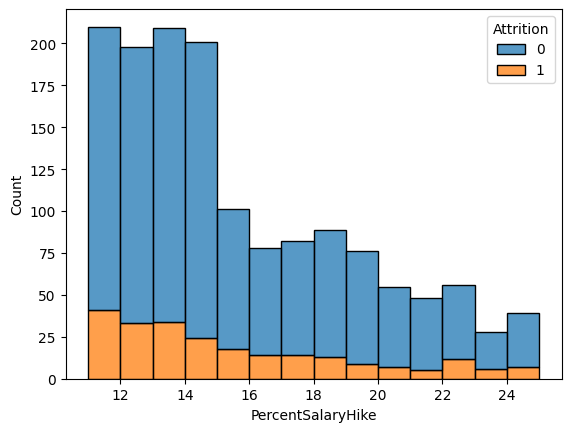

In [57]:
sns.histplot(data=df,x='PercentSalaryHike',hue='Attrition',multiple="stack",)

<Axes: xlabel='StockOptionLevel', ylabel='Count'>

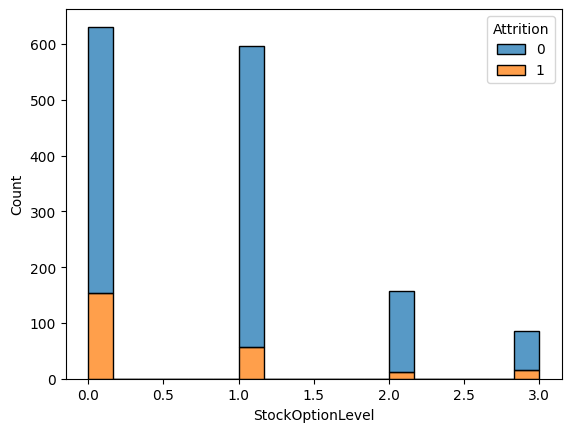

In [58]:
sns.histplot(data=df,x='StockOptionLevel',hue='Attrition',multiple="stack",)

<Axes: xlabel='TrainingTimesLastYear', ylabel='Count'>

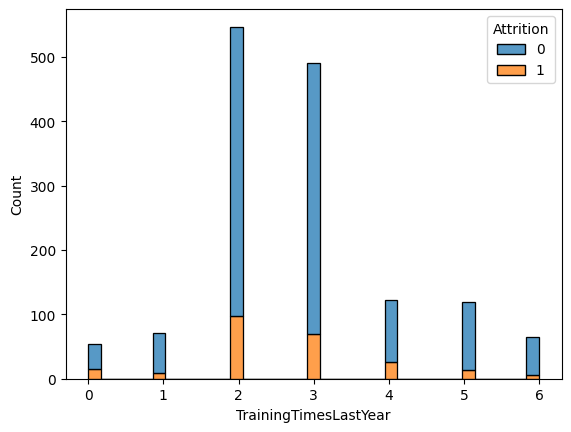

In [59]:
sns.histplot(data=df,x='TrainingTimesLastYear',hue='Attrition',multiple="stack",)

**📌 Note:**

It seems that EnvironmentSatisfaction, JobSatisfaction, PerformanceRating, and RelationshipSatisfaction features don't have big impact on the detrmination of Attrition of employees.

<Axes: xlabel='Age', ylabel='Count'>

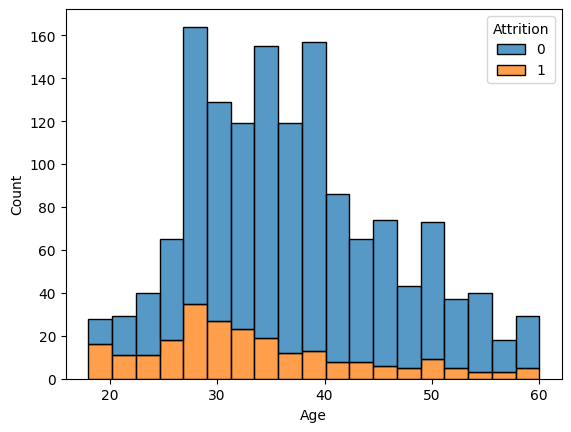

In [60]:
sns.histplot(data=df,x='Age',hue='Attrition',multiple="stack",)

<Axes: xlabel='MonthlyIncome', ylabel='Count'>

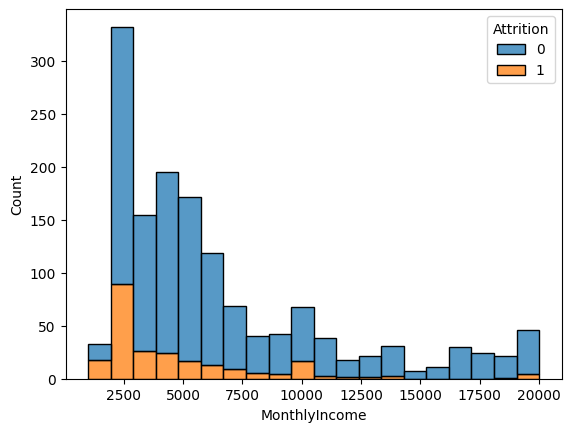

In [61]:
sns.histplot(data=df,x='MonthlyIncome',hue='Attrition',multiple="stack",)

<Axes: xlabel='YearsAtCompany', ylabel='Count'>

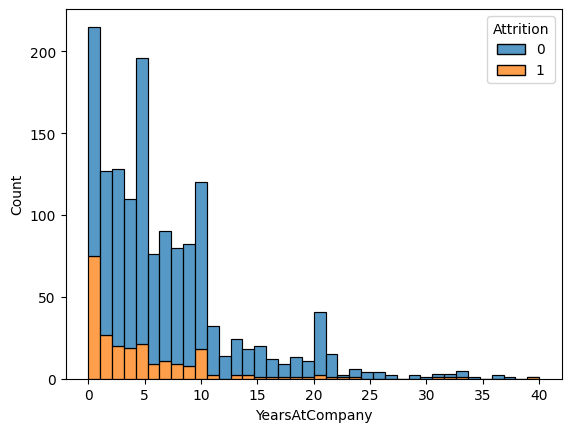

In [62]:
sns.histplot(data=df,x='YearsAtCompany',hue='Attrition',multiple="stack",)

<Axes: xlabel='TotalWorkingYears', ylabel='Count'>

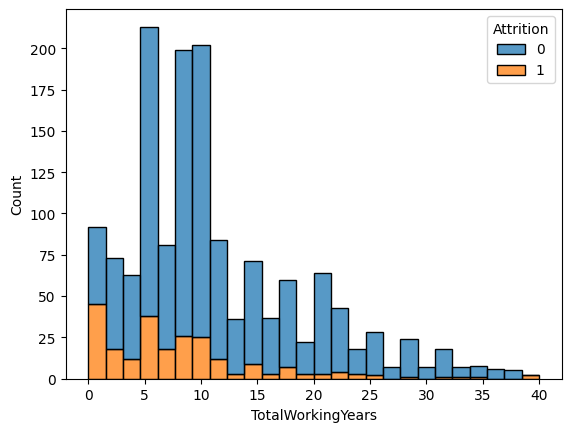

In [63]:
sns.histplot(data=df,x='TotalWorkingYears',hue='Attrition',multiple="stack",)

**📝 Conclusions:**

The workers with low JobLevel, MonthlyIncome, YearAtCompany, and TotalWorkingYears are more likely to quit there jobs.
BusinessTravel : The workers who travel alot are more likely to quit then other employees.

Department : The worker in Research & Development are more likely to stay then the workers on other departement.

EducationField : The workers with Human Resources and Technical Degree are more likely to quit then employees from other fields of educations.

Gender : The Male are more likely to quit.

JobRole : The workers in Laboratory Technician, Sales Representative, and Human Resources are more likely to quit the workers in other positions.

MaritalStatus : The workers who have Single marital status are more likely to quit the Married, and Divorced.

OverTime : The workers who work more hours are likely to quit then others.

**📉 Correlation Matrix:**

<Axes: >

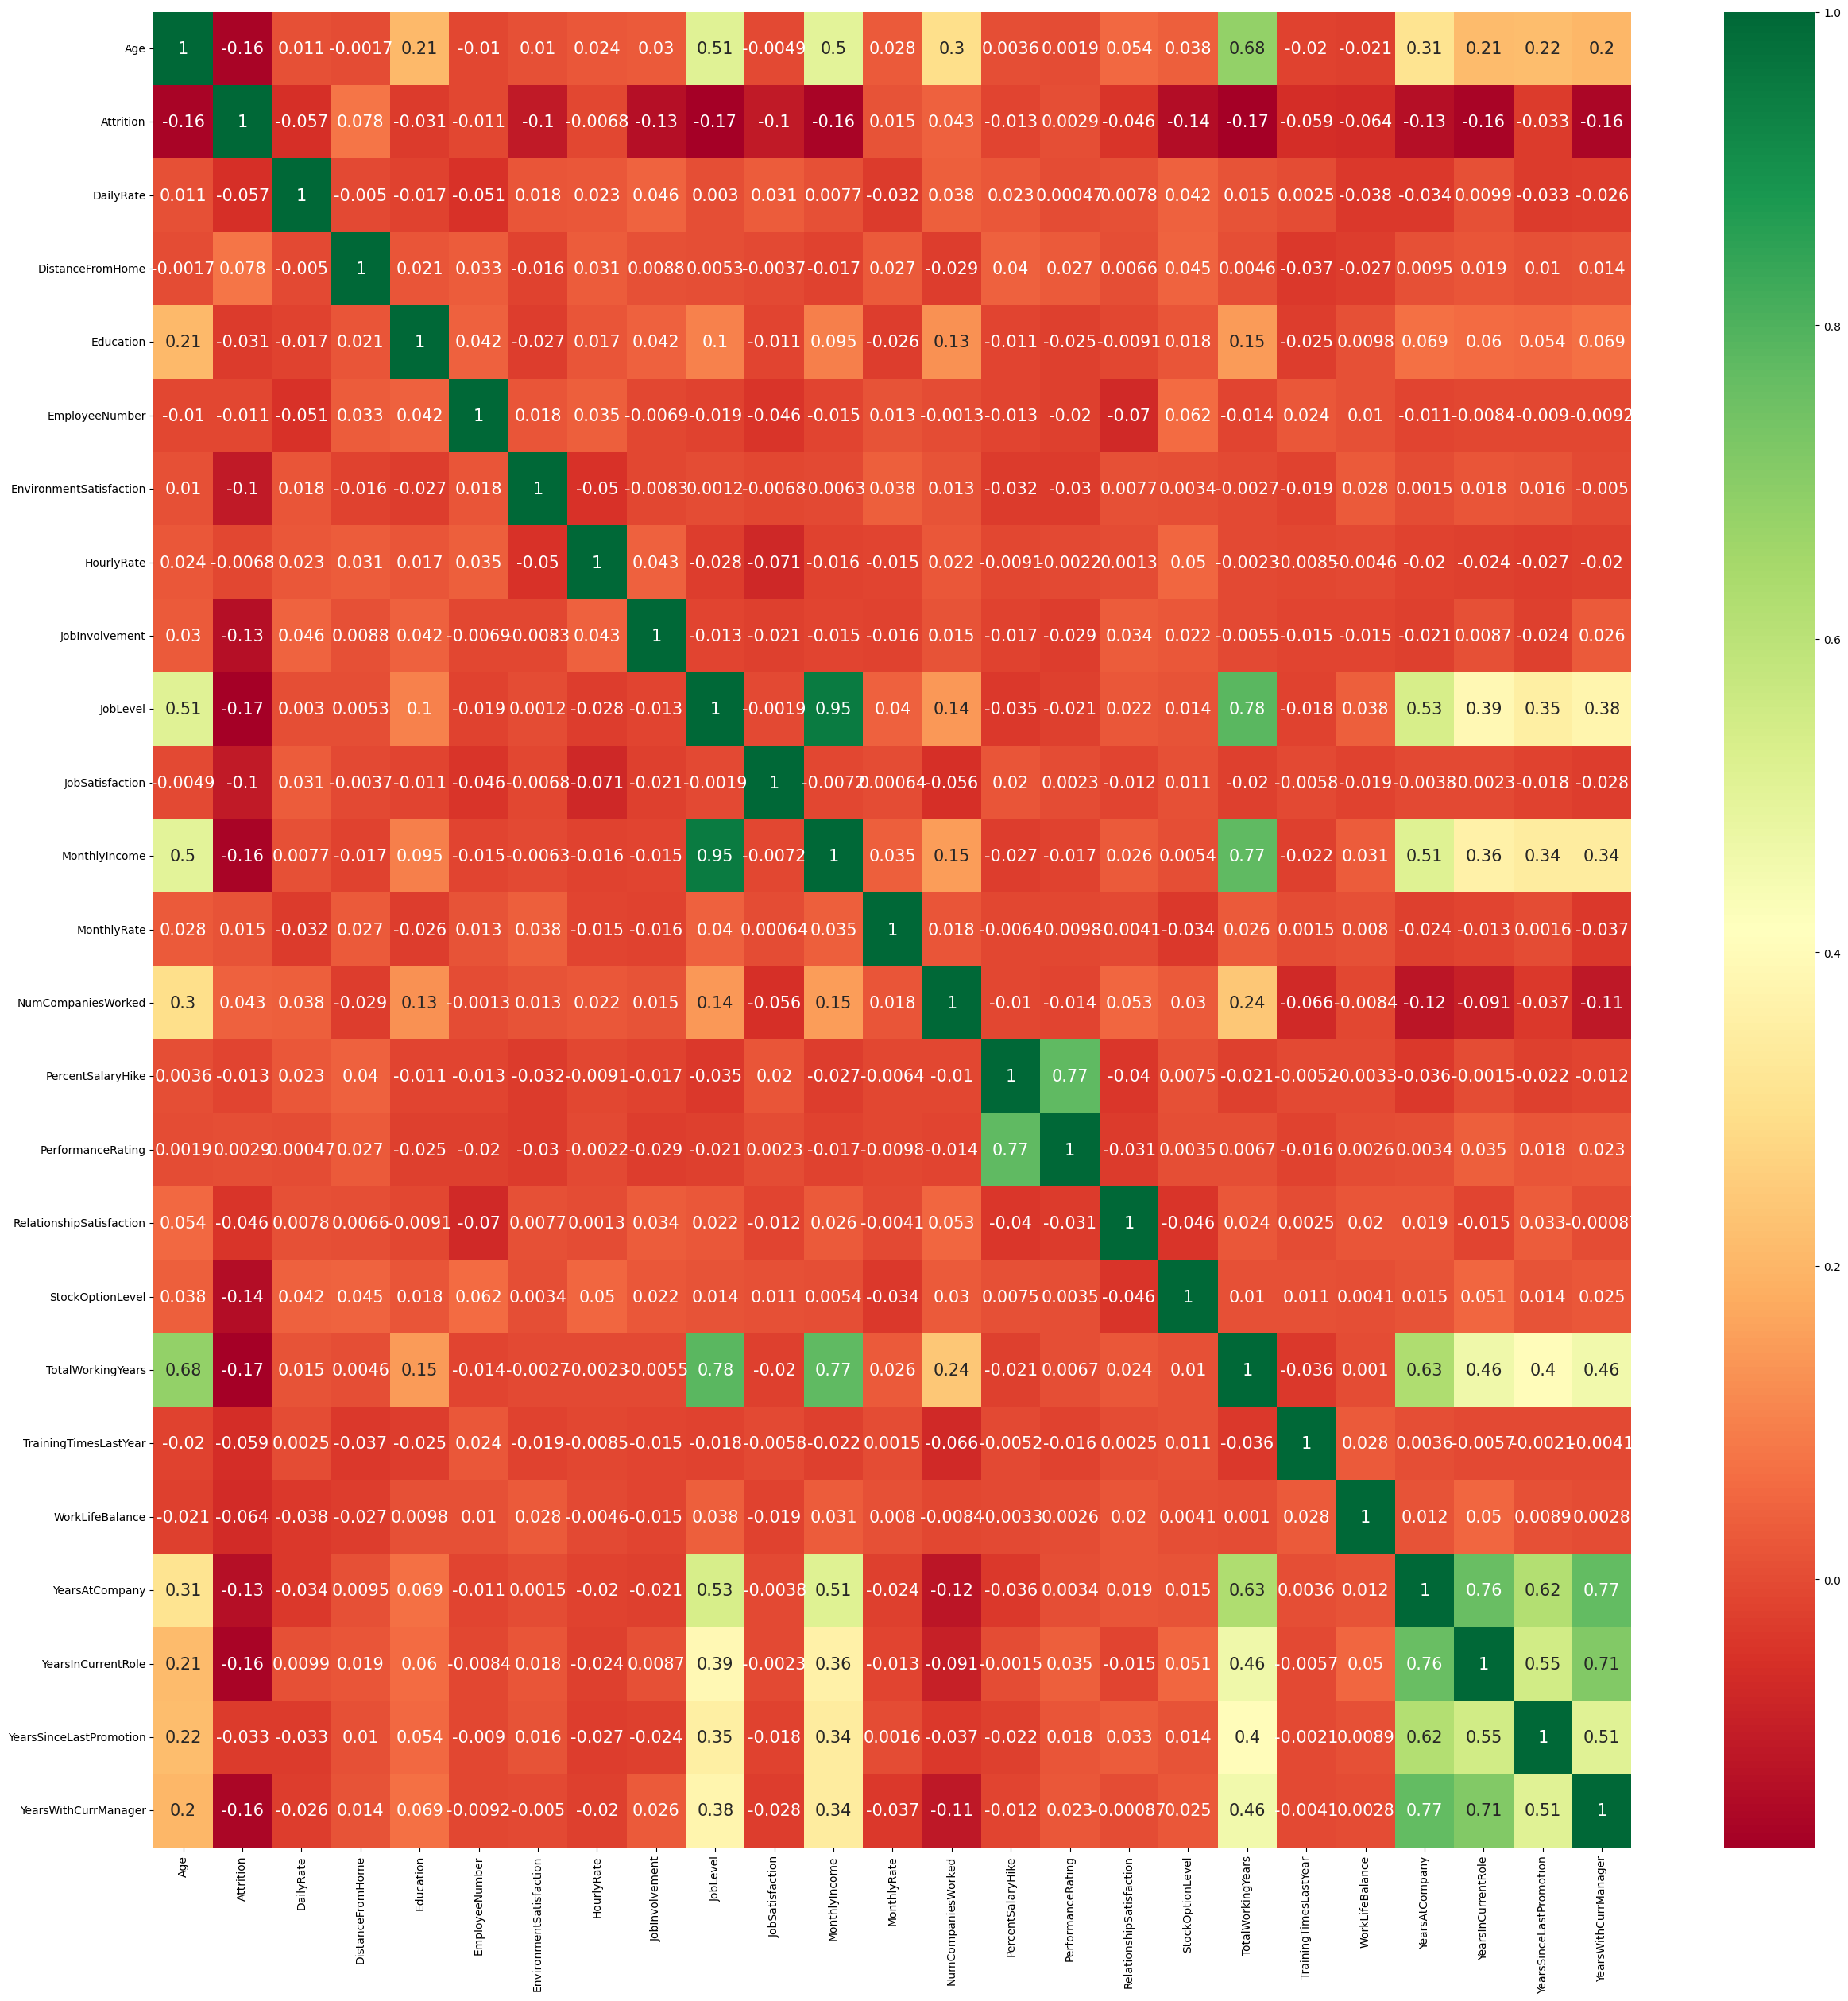

In [64]:
plt.figure(figsize=(30, 30))
sns.heatmap(df.select_dtypes(include=['number']).corr(), annot=True, cmap="RdYlGn", annot_kws={"size":15})

<Axes: >

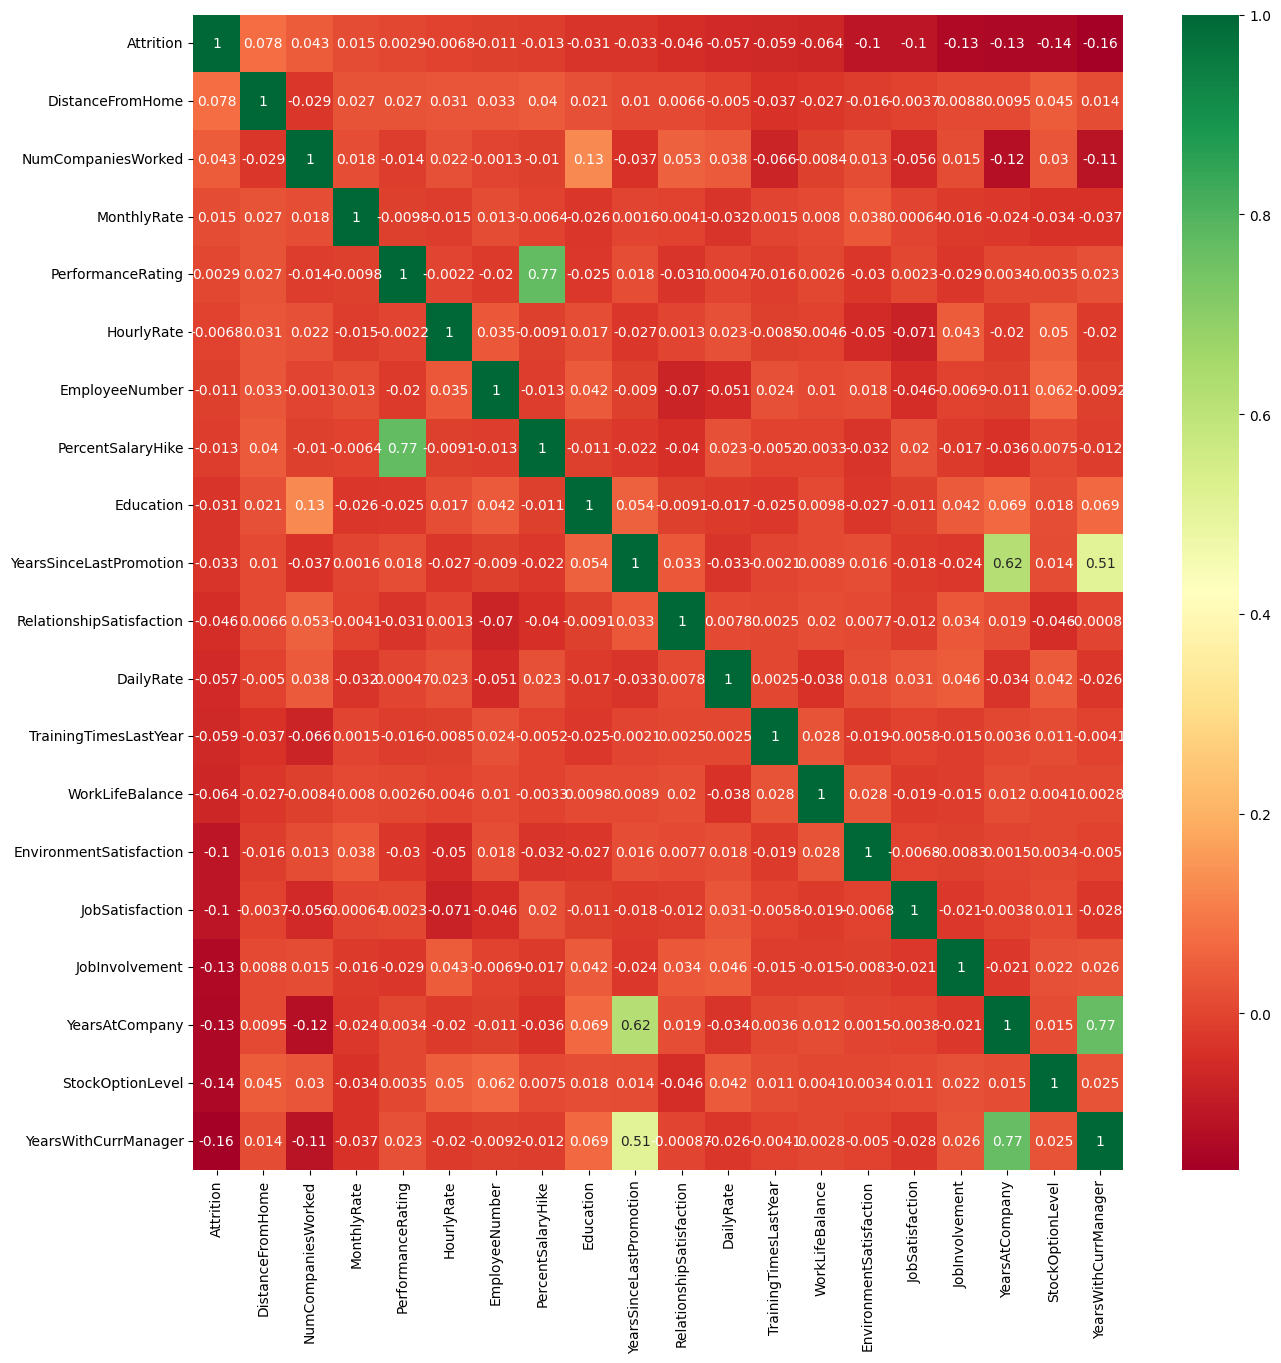

In [65]:
col = df.select_dtypes(include=['number']).corr().nlargest(20, "Attrition").Attrition.index
plt.figure(figsize=(15, 15))
sns.heatmap(df[col].corr(), annot=True, cmap="RdYlGn", annot_kws={"size":10})

c:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


<Axes: >

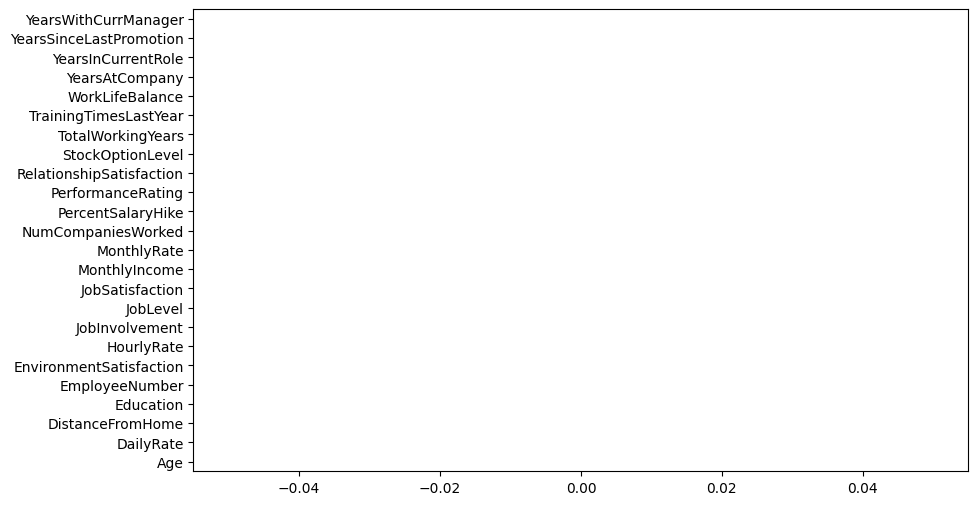

In [66]:
attrition_numeric = data['Attrition'].apply(lambda x: 1 if x == 'Yes' else 0)

# Calculate correlations and plot
df.drop('Attrition', axis=1).select_dtypes(include=['number']).corrwith(attrition_numeric).plot(kind='barh', figsize=(10, 6))

**📝 Analysis of correlation results (sample analysis):**

* Monthly income is highly correlated with Job level.
* Job level is highly correlated with total working hours.
* Monthly income is highly correlated with total working hours.
* Age is also positively correlated with the Total working hours.
* Marital status and stock option level are negatively correlated

<Axes: xlabel='MonthlyIncome', ylabel='Count'>

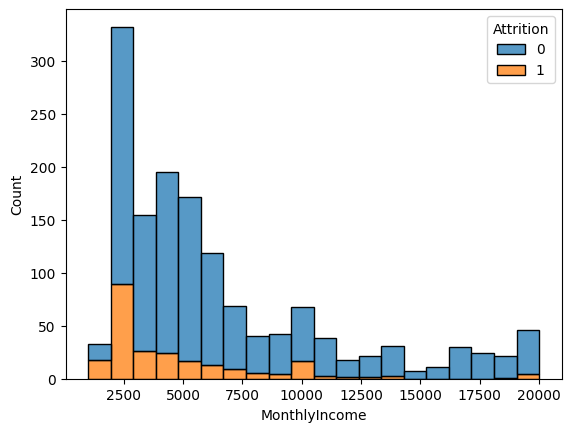

In [67]:
sns.histplot(data=df,x='MonthlyIncome',hue='Attrition',multiple="stack",)

#### **🔨 Data Processing**

In [68]:
# Transform categorical data into dummies
dummy_col = [column for column in df.drop('Attrition', axis=1).columns if df[column].nunique() < 20]
data = pd.get_dummies(df, columns=dummy_col, drop_first=True, dtype='uint8')
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Columns: 137 entries, Age to YearsWithCurrManager_17
dtypes: int64(10), uint8(127)
memory usage: 297.3 KB


In [69]:
print(data.shape)

# Remove duplicate Features
data = data.T.drop_duplicates()
data = data.T

# Remove Duplicate Rows
data.drop_duplicates(inplace=True)

print(data.shape)

(1470, 137)
(1470, 137)


In [70]:
data.shape

(1470, 137)

<Axes: >

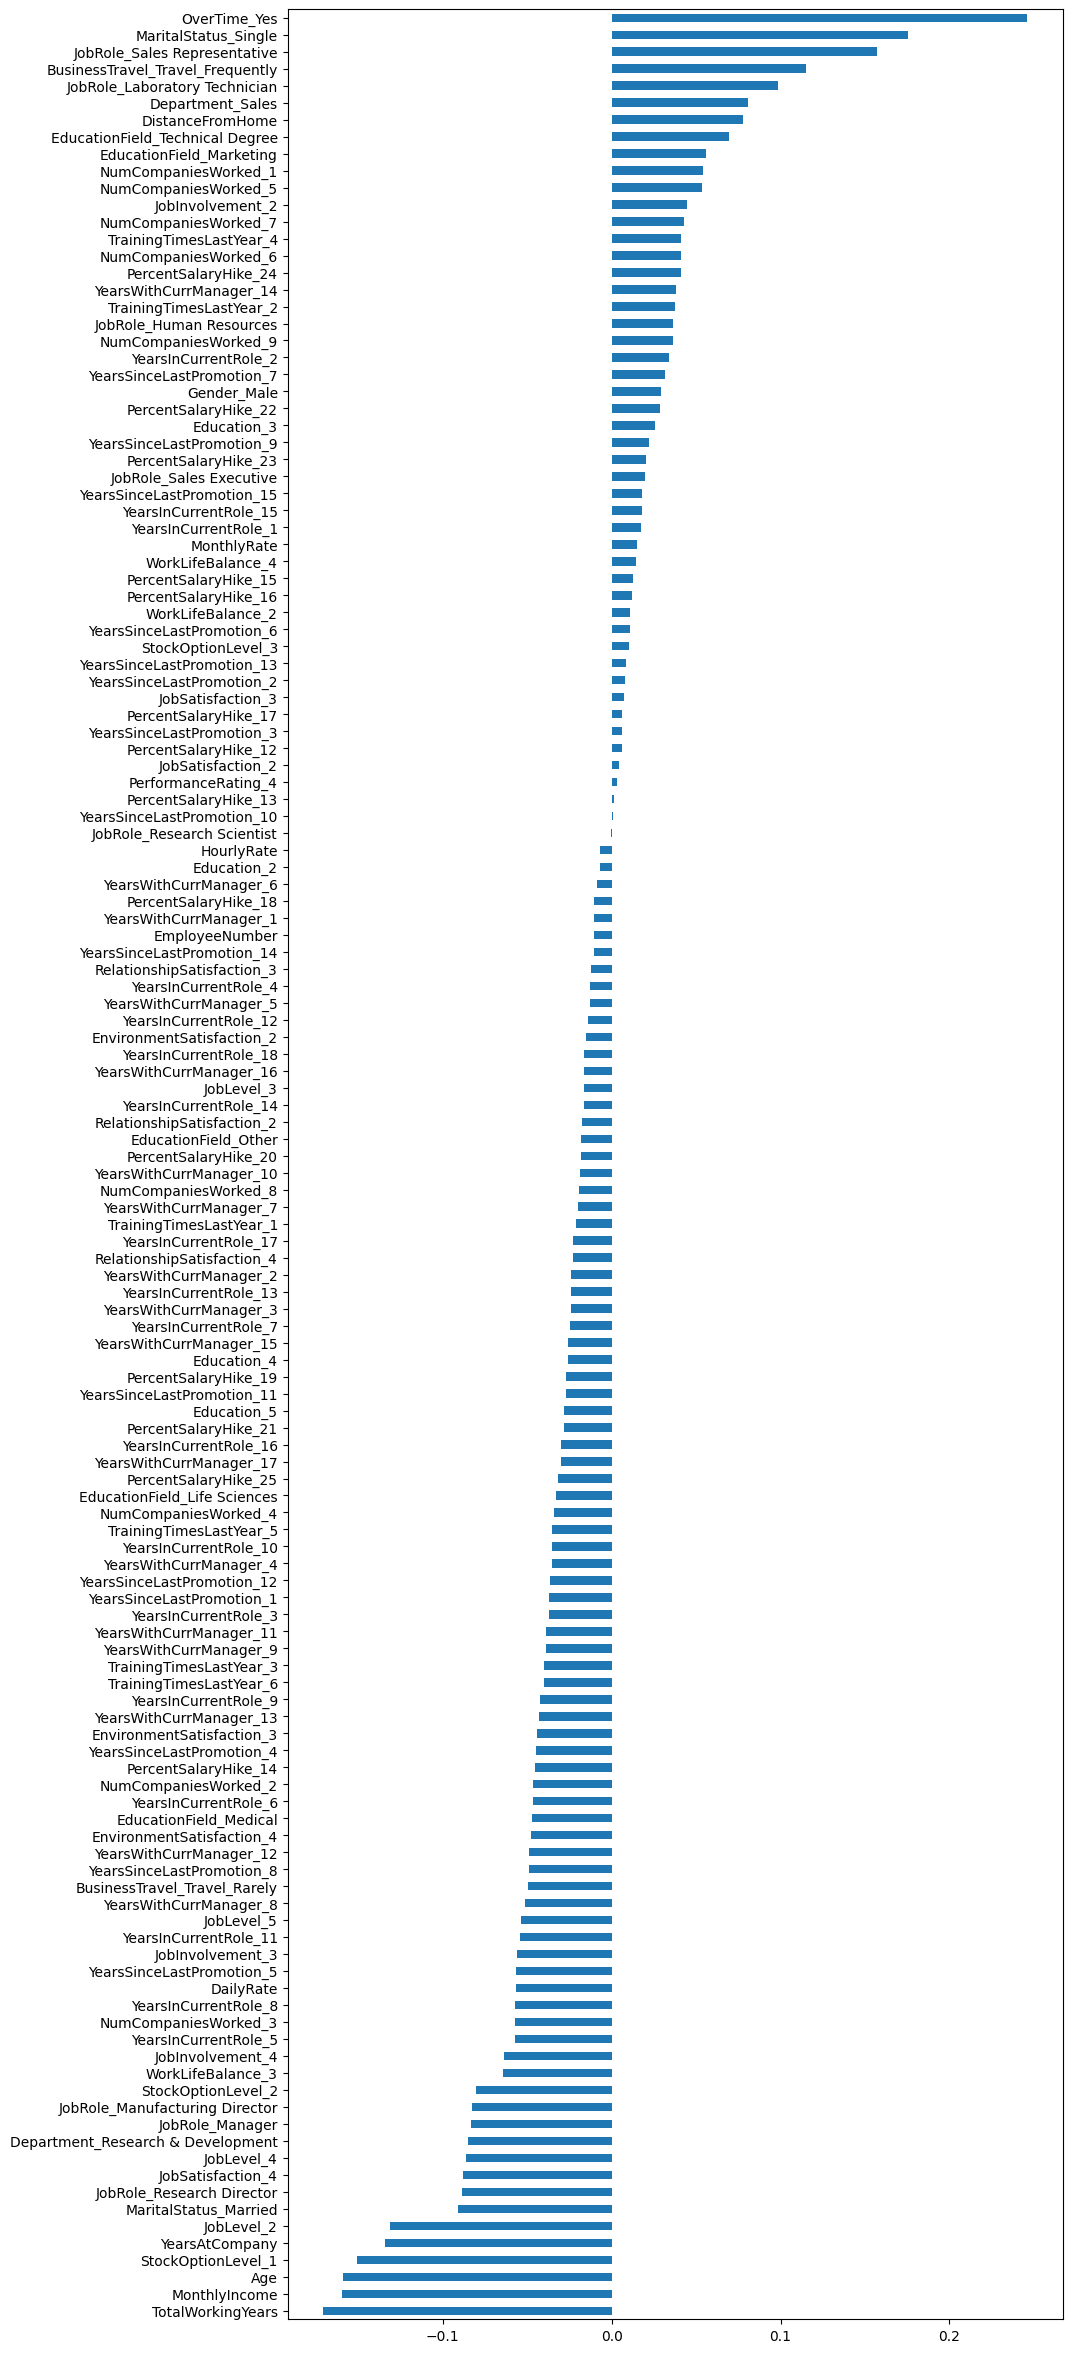

In [71]:
data.drop("Attrition", axis=1).select_dtypes(include=["number"]).corrwith(data["Attrition"]).sort_values().plot(kind="barh", figsize=(10, 30))

<Axes: >

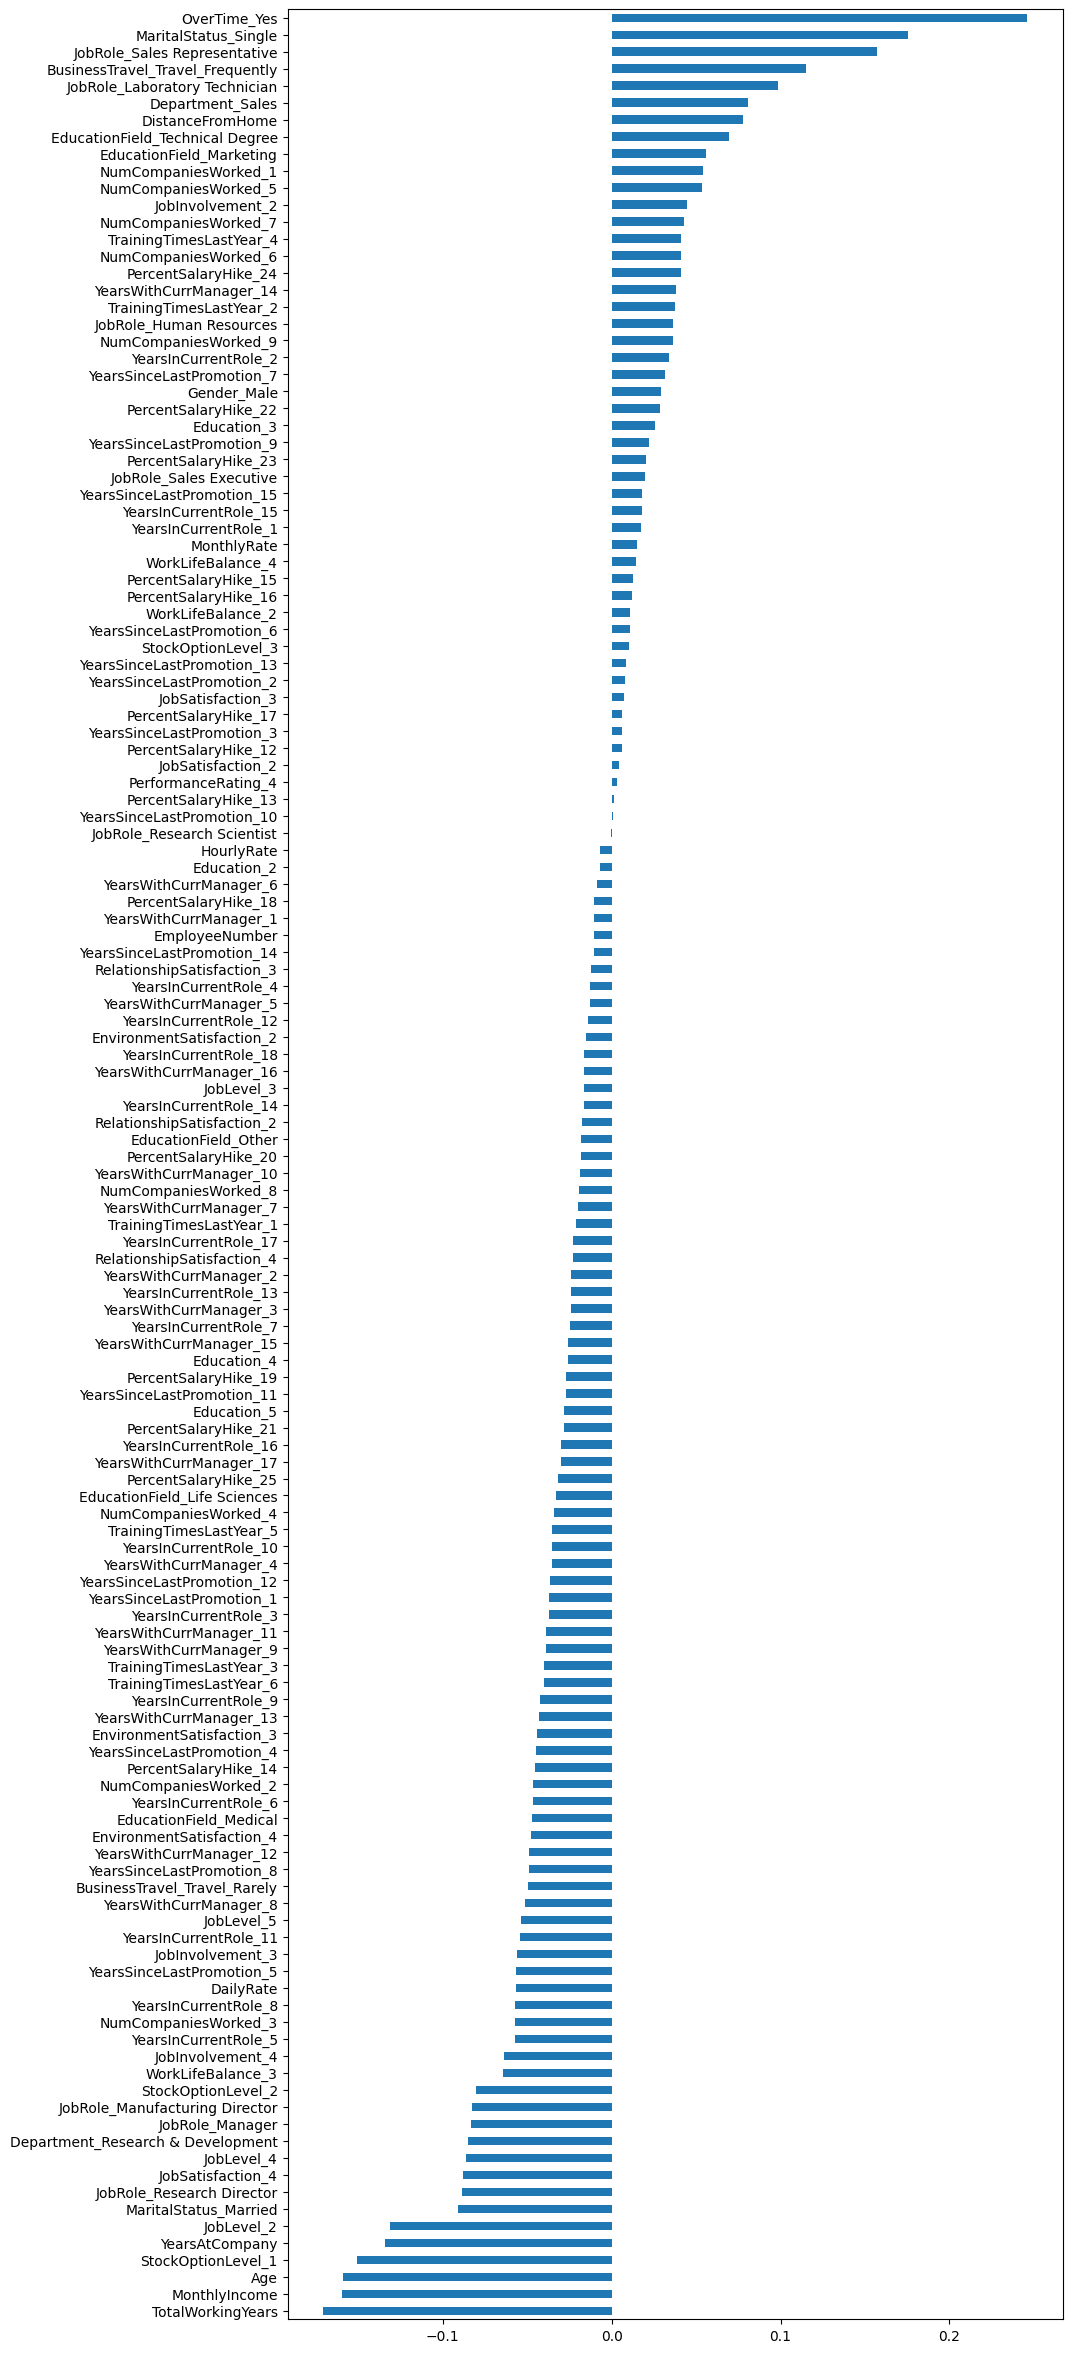

In [72]:
data.drop('Attrition', axis=1).select_dtypes(include=['number']).corrwith(data.Attrition).dropna().sort_values().plot(kind='barh', figsize=(10, 30))

In [73]:
feature_correlation = data.drop('Attrition', axis=1).corrwith(data.Attrition).sort_values()
model_col = feature_correlation[np.abs(feature_correlation) > 0.02].index
len(model_col)

92

#### **🤖 Applying machine learning algorithms**

In [74]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler

In [75]:
X = data.drop('Attrition', axis=1)
y = data.Attrition

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42,stratify=y)

scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)
X_std = scaler.transform(X)

In [ ]:
# gives feature importance according to model
def feature_imp(df, model):
    fi = pd.DataFrame()
    fi["feature"] = df.columns
    fi["importance"] = model.feature_importances_
    return fi.sort_values(by="importance", ascending=False)

**🎯 What defines success?**

We have an imbalanced data, so if we predict that all our employees will stay we'll have an accuracy of 83.90%.

In [77]:
y_test.value_counts()[0] / y_test.shape[0]

np.float64(0.8390022675736961)

In [78]:
stay = (y_train.value_counts()[0] / y_train.shape)[0]
leave = (y_train.value_counts()[1] / y_train.shape)[0]

print("===============TRAIN=================")
print(f"Staying Rate: {stay * 100:.2f}%")
print(f"Leaving Rate: {leave * 100 :.2f}%")

stay = (y_test.value_counts()[0] / y_test.shape)[0]
leave = (y_test.value_counts()[1] / y_test.shape)[0]

print("===============TEST=================")
print(f"Staying Rate: {stay * 100:.2f}%")
print(f"Leaving Rate: {leave * 100 :.2f}%")

===============TRAIN=================
Staying Rate: 83.87%
Leaving Rate: 16.13%
===============TEST=================
Staying Rate: 83.90%
Leaving Rate: 16.10%


In [79]:
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report, roc_auc_score

def evaluate(model, X_train, X_test, y_train, y_test):
    y_test_pred = model.predict(X_test)
    y_train_pred = model.predict(X_train)

    print("Training Result: -------------------------------")
    clf_report = pd.DataFrame(classification_report(y_train, y_train_pred, output_dict=True))
    print(f"1. confusion_matrix:\n{confusion_matrix(y_train, y_train_pred)}")
    print(f"2. accuracy_acore: {round(accuracy_score(y_train, y_train_pred)*100,2):.2f} %")
    print(f"3. classification_report:\n{clf_report}")

    print("\nTesting Result: -------------------------------")
    clf_report = pd.DataFrame(classification_report(y_test, y_test_pred, output_dict=True))
    print(f"1. confusion_matrix:\n{confusion_matrix(y_test, y_test_pred)}")
    print(f"2. accuracy_acore: {round(accuracy_score(y_test, y_test_pred)*100,2):.2f} %")
    print(f"3. classification_report:\n{clf_report}")


##### **✔️ 1. Logistic Regression**

In [138]:
from sklearn.linear_model import LogisticRegression

lr_clf = LogisticRegression(C=1.0)
lr_clf.fit(X_train_std, y_train)

evaluate(lr_clf, X_train_std, X_test_std, y_train, y_test)

Training Result: -------------------------------
1. confusion_matrix:
[[847  16]
 [ 57 109]]
2. accuracy_acore: 92.91 %
3. classification_report:
                    0           1  accuracy    macro avg  weighted avg
precision    0.936947    0.872000  0.929057     0.904473      0.926470
recall       0.981460    0.656627  0.929057     0.819043      0.929057
f1-score     0.958687    0.749141  0.929057     0.853914      0.924883
support    863.000000  166.000000  0.929057  1029.000000   1029.000000

Testing Result: -------------------------------
1. confusion_matrix:
[[343  27]
 [ 42  29]]
2. accuracy_acore: 84.35 %
3. classification_report:
                    0          1  accuracy   macro avg  weighted avg
precision    0.890909   0.517857  0.843537    0.704383      0.830849
recall       0.927027   0.408451  0.843537    0.667739      0.843537
f1-score     0.908609   0.456693  0.843537    0.682651      0.835852
support    370.000000  71.000000  0.843537  441.000000    441.000000


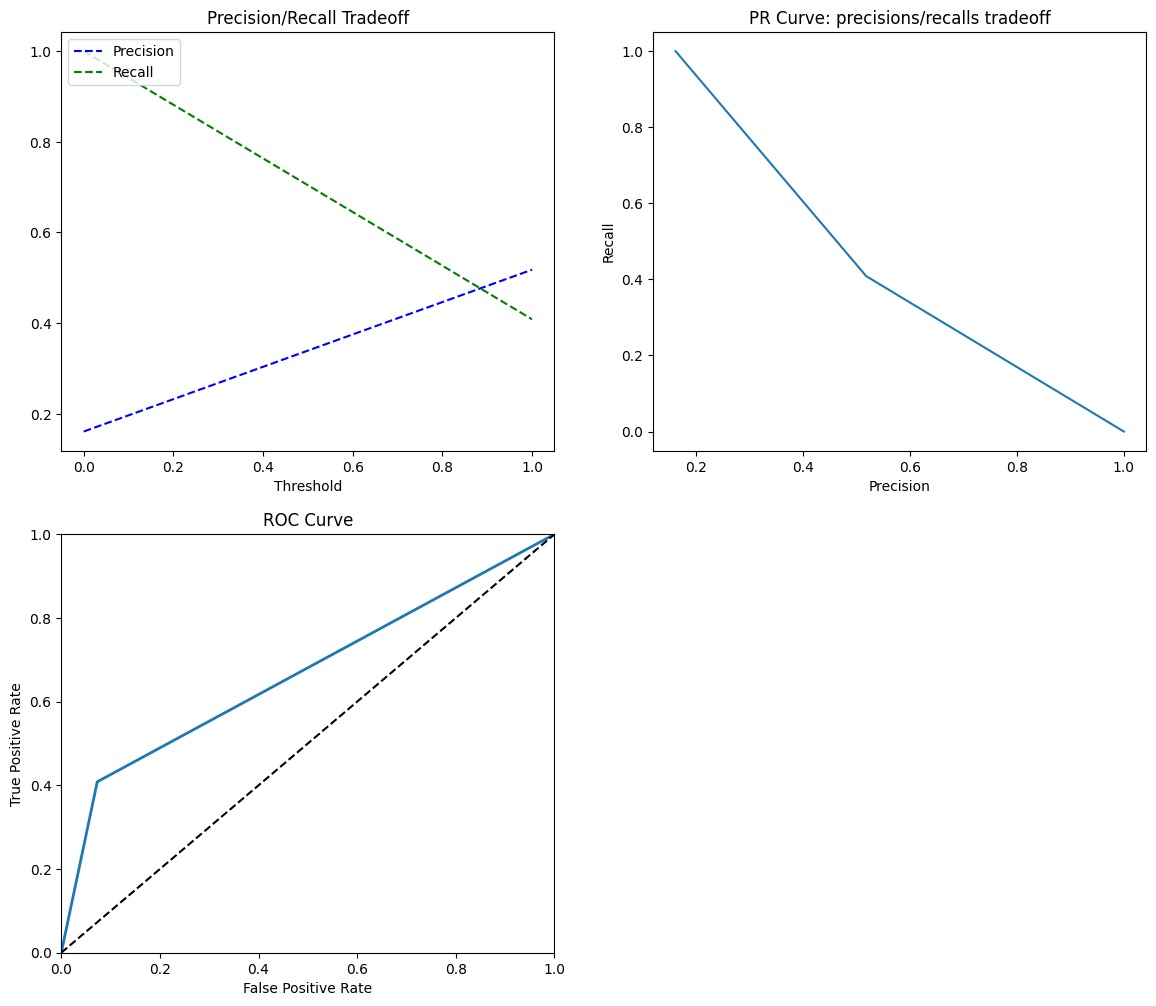

In [81]:
from sklearn.metrics import precision_recall_curve, roc_curve

def plot_precision_recall_vs_threshold(precisions, recalls, thresholds):
    plt.plot(thresholds, precisions[:-1], "b--", label="Precision")
    plt.plot(thresholds, recalls[:-1], "g--", label="Recall")
    plt.xlabel("Threshold")
    plt.legend(loc="upper left")
    plt.title("Precision/Recall Tradeoff")
    

def plot_roc_curve(fpr, tpr, label=None):
    plt.plot(fpr, tpr, linewidth=2, label=label)
    plt.plot([0, 1], [0, 1], "k--")
    plt.axis([0, 1, 0, 1])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve')
    
    
precisions, recalls, thresholds = precision_recall_curve(y_test, lr_clf.predict(X_test_std))
plt.figure(figsize=(14, 25))
plt.subplot(4, 2, 1)
plot_precision_recall_vs_threshold(precisions, recalls, thresholds)

plt.subplot(4, 2, 2)
plt.plot(precisions, recalls)
plt.xlabel("Precision")
plt.ylabel("Recall")
plt.title("PR Curve: precisions/recalls tradeoff");

plt.subplot(4, 2, 3)
fpr, tpr, thresholds = roc_curve(y_test, lr_clf.predict(X_test_std))
plot_roc_curve(fpr, tpr)


In [82]:
scores_dict = {
    'Logistic Regression': {
        'Train': roc_auc_score(y_train, lr_clf.predict(X_train.values)),
        'Test': roc_auc_score(y_test, lr_clf.predict(X_test.values)),
    },
}

##### **✔️ Random Forest Classifier**

In [83]:
from sklearn.ensemble import RandomForestClassifier

rf_clf = RandomForestClassifier(n_estimators=100, bootstrap=False,)
rf_clf.fit(X_train, y_train)
evaluate(rf_clf, X_train, X_test, y_train, y_test)

Training Result: -------------------------------
1. confusion_matrix:
[[863   0]
 [  0 166]]
2. accuracy_acore: 100.00 %
3. classification_report:
               0      1  accuracy  macro avg  weighted avg
precision    1.0    1.0       1.0        1.0           1.0
recall       1.0    1.0       1.0        1.0           1.0
f1-score     1.0    1.0       1.0        1.0           1.0
support    863.0  166.0       1.0     1029.0        1029.0

Testing Result: -------------------------------
1. confusion_matrix:
[[360  10]
 [ 62   9]]
2. accuracy_acore: 83.67 %
3. classification_report:
                    0          1  accuracy   macro avg  weighted avg
precision    0.853081   0.473684  0.836735    0.663382      0.791999
recall       0.972973   0.126761  0.836735    0.549867      0.836735
f1-score     0.909091   0.200000  0.836735    0.554545      0.794929
support    370.000000  71.000000  0.836735  441.000000    441.000000


In [84]:
from sklearn.model_selection import RandomizedSearchCV

In [85]:
# 1. parameter grid
param_grid = dict(
    n_estimators= [100, 500, 900], 
    max_features= ['sqrt','log2'],
    max_depth= [2, 3, 5, 10, 15, None], 
    min_samples_split= [2, 5, 10],
    min_samples_leaf= [1, 2, 4], 
    bootstrap= [True, False]
)

# 2. Initialise the classifier
rf_clf = RandomForestClassifier(random_state=42)

# 3. Configure the grid search
#search = GridSearchCV(rf_clf, param_grid=param_grid, scoring='roc_auc', cv=5, verbose=1, n_jobs=-1)
search = RandomizedSearchCV(
    estimator=rf_clf, 
    param_distributions=param_grid, 
    n_iter=20,            # Controls the speed vs thoroughness trade-off
    scoring='roc_auc', 
    cv=5, 
    verbose=1, 
    n_jobs=-1, 
    random_state=42       # Ensures reproducibility
)

# 4. Fit the grid search on your training data
search.fit(X_train, y_train)

# 5. Build and train the final model using the absolute best parameters found
rf_clf = RandomForestClassifier(**search.best_params_, class_weight='balanced',random_state=42)
rf_clf.fit(X_train, y_train)

# 6. Evaluate your tuned model
evaluate(rf_clf, X_train, X_test, y_train, y_test)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Training Result: -------------------------------
1. confusion_matrix:
[[756 107]
 [ 55 111]]
2. accuracy_acore: 84.26 %
3. classification_report:
                    0           1  accuracy    macro avg  weighted avg
precision    0.932182    0.509174  0.842566     0.720678      0.863942
recall       0.876014    0.668675  0.842566     0.772344      0.842566
f1-score     0.903226    0.578125  0.842566     0.740675      0.850780
support    863.000000  166.000000  0.842566  1029.000000   1029.000000

Testing Result: -------------------------------
1. confusion_matrix:
[[308  62]
 [ 29  42]]
2. accuracy_acore: 79.37 %
3. classification_report:
                    0          1  accuracy   macro avg  weighted avg
precision    0.913947   0.403846  0.793651    0.658896      0.831822
recall       0.832432   0.591549  0.793651    0.711991      0.793651
f1-score     0.871287   0.480000  0.793651    0.675644      0.808291
support    370.

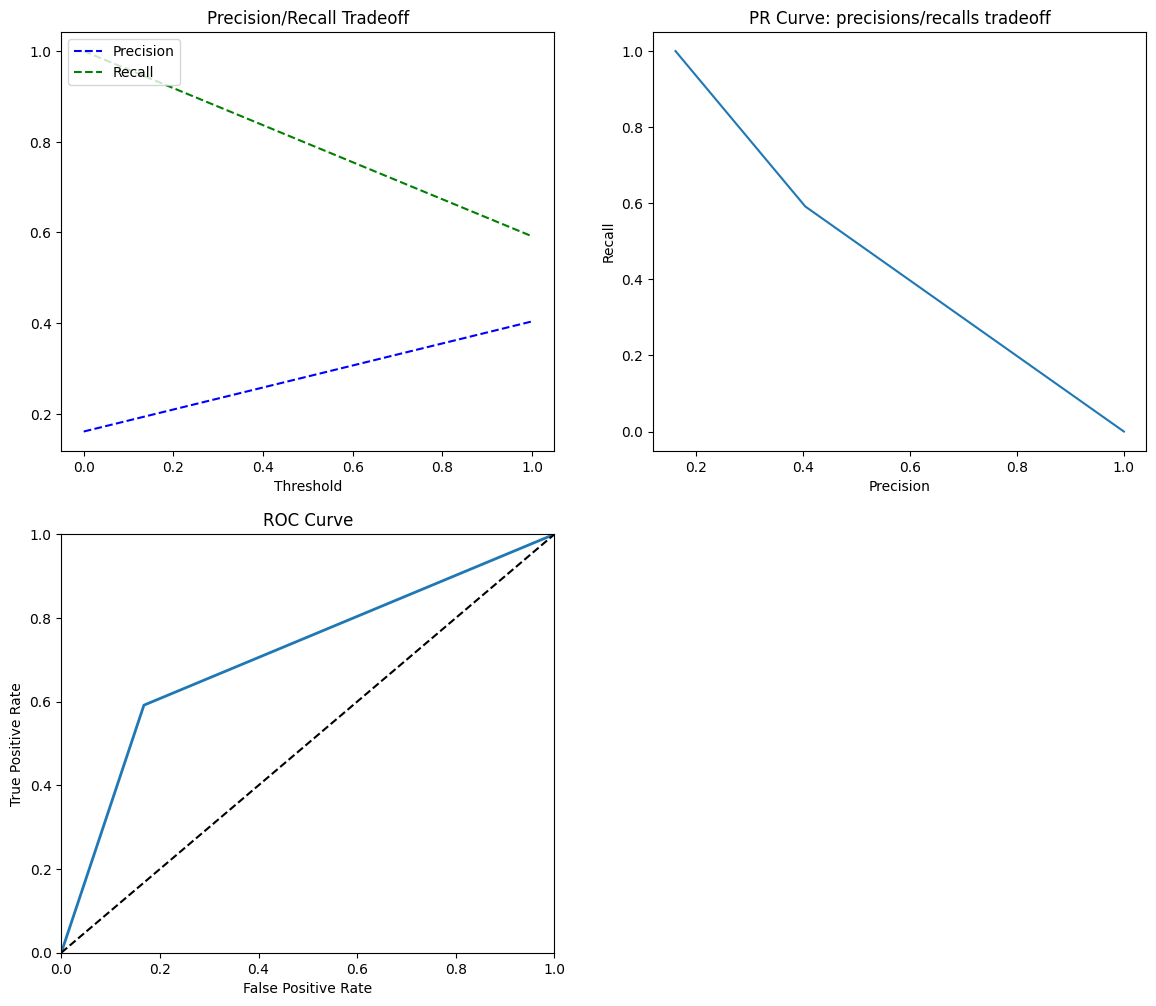

In [86]:
precisions, recalls, thresholds = precision_recall_curve(y_test, rf_clf.predict(X_test))
plt.figure(figsize=(14, 25))
plt.subplot(4, 2, 1)
plot_precision_recall_vs_threshold(precisions, recalls, thresholds)

plt.subplot(4, 2, 2)
plt.plot(precisions, recalls)
plt.xlabel("Precision")
plt.ylabel("Recall")
plt.title("PR Curve: precisions/recalls tradeoff");

plt.subplot(4, 2, 3)
fpr, tpr, thresholds = roc_curve(y_test, rf_clf.predict(X_test))
plot_roc_curve(fpr, tpr)

In [87]:
scores_dict['Random Forest'] = {
        'Train': roc_auc_score(y_train, rf_clf.predict(X_train)),
        'Test': roc_auc_score(y_test, rf_clf.predict(X_test)),
    }

Text(0.5, 1.0, 'Feature Importance according to Random Forest')

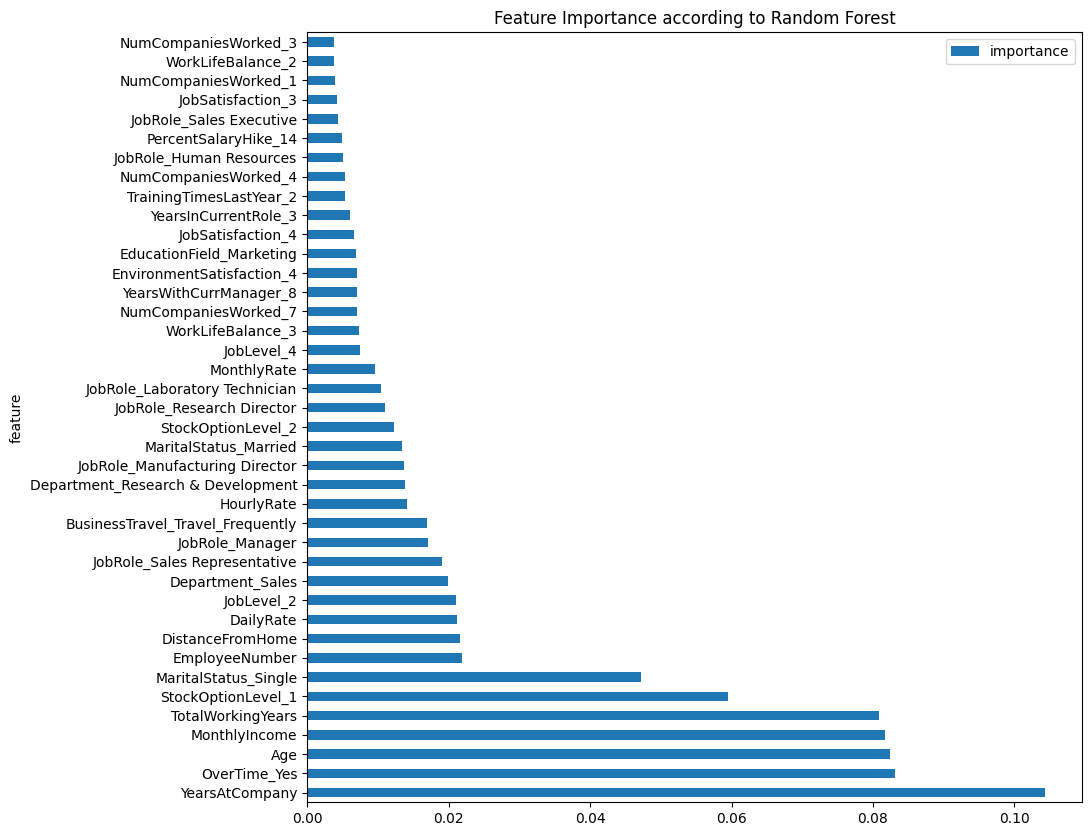

In [88]:
df = feature_imp(X, rf_clf)[:40]
df.set_index('feature', inplace=True)
df.plot(kind='barh', figsize=(10, 10))
plt.title('Feature Importance according to Random Forest')

##### **✔️ Support Vector Machine**

In [89]:
from sklearn.svm import SVC

svm_clf = SVC(kernel='linear')
svm_clf.fit(X_train_std, y_train)

evaluate(svm_clf, X_train_std, X_test_std, y_train, y_test)

Training Result: -------------------------------
1. confusion_matrix:
[[857   6]
 [ 48 118]]
2. accuracy_acore: 94.75 %
3. classification_report:
                    0           1  accuracy    macro avg  weighted avg
precision    0.946961    0.951613  0.947522     0.949287      0.947712
recall       0.993048    0.710843  0.947522     0.851945      0.947522
f1-score     0.969457    0.813793  0.947522     0.891625      0.944345
support    863.000000  166.000000  0.947522  1029.000000   1029.000000

Testing Result: -------------------------------
1. confusion_matrix:
[[345  25]
 [ 46  25]]
2. accuracy_acore: 83.90 %
3. classification_report:
                    0          1  accuracy   macro avg  weighted avg
precision    0.882353   0.500000  0.839002    0.691176      0.820795
recall       0.932432   0.352113  0.839002    0.642273      0.839002
f1-score     0.906702   0.413223  0.839002    0.659962      0.827253
support    370.000000  71.000000  0.839002  441.000000    441.000000


In [90]:
svm_clf = SVC(class_weight='balanced',random_state=42)

param_dist = {
    'C': [0.1, 1, 10, 100], 
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto', 0.001, 0.0001] # 'scale' and 'auto' are highly efficient for RBF
}

#search = GridSearchCV(svm_clf, param_grid=param_grid, scoring='roc_auc', cv=3, refit=True, verbose=1)
search = RandomizedSearchCV(
    estimator=svm_clf, 
    param_distributions=param_dist, 
    n_iter=15,            # Limit to 15 random combinations
    scoring='roc_auc', 
    cv=3,                 # Keeps cv=3 as requested
    verbose=1, 
    n_jobs=-1,            # FIXED: Uses all available CPU cores to speed up training
    random_state=42
)

search.fit(X_train_std, y_train)

Fitting 3 folds for each of 15 candidates, totalling 45 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVC(class_wei...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'C': [0.1, 1, ...], 'gamma': ['scale', 'auto', ...], 'kernel': ['linear', 'rbf']}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",15
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if 

In [91]:
svm_clf = SVC(**search.best_params_)
svm_clf.fit(X_train_std, y_train)

evaluate(svm_clf, X_train_std, X_test_std, y_train, y_test)

Training Result: -------------------------------
1. confusion_matrix:
[[863   0]
 [  0 166]]
2. accuracy_acore: 100.00 %
3. classification_report:
               0      1  accuracy  macro avg  weighted avg
precision    1.0    1.0       1.0        1.0           1.0
recall       1.0    1.0       1.0        1.0           1.0
f1-score     1.0    1.0       1.0        1.0           1.0
support    863.0  166.0       1.0     1029.0        1029.0

Testing Result: -------------------------------
1. confusion_matrix:
[[357  13]
 [ 47  24]]
2. accuracy_acore: 86.39 %
3. classification_report:
                    0          1  accuracy   macro avg  weighted avg
precision    0.883663   0.648649  0.863946    0.766156      0.845827
recall       0.964865   0.338028  0.863946    0.651447      0.863946
f1-score     0.922481   0.444444  0.863946    0.683463      0.845518
support    370.000000  71.000000  0.863946  441.000000    441.000000


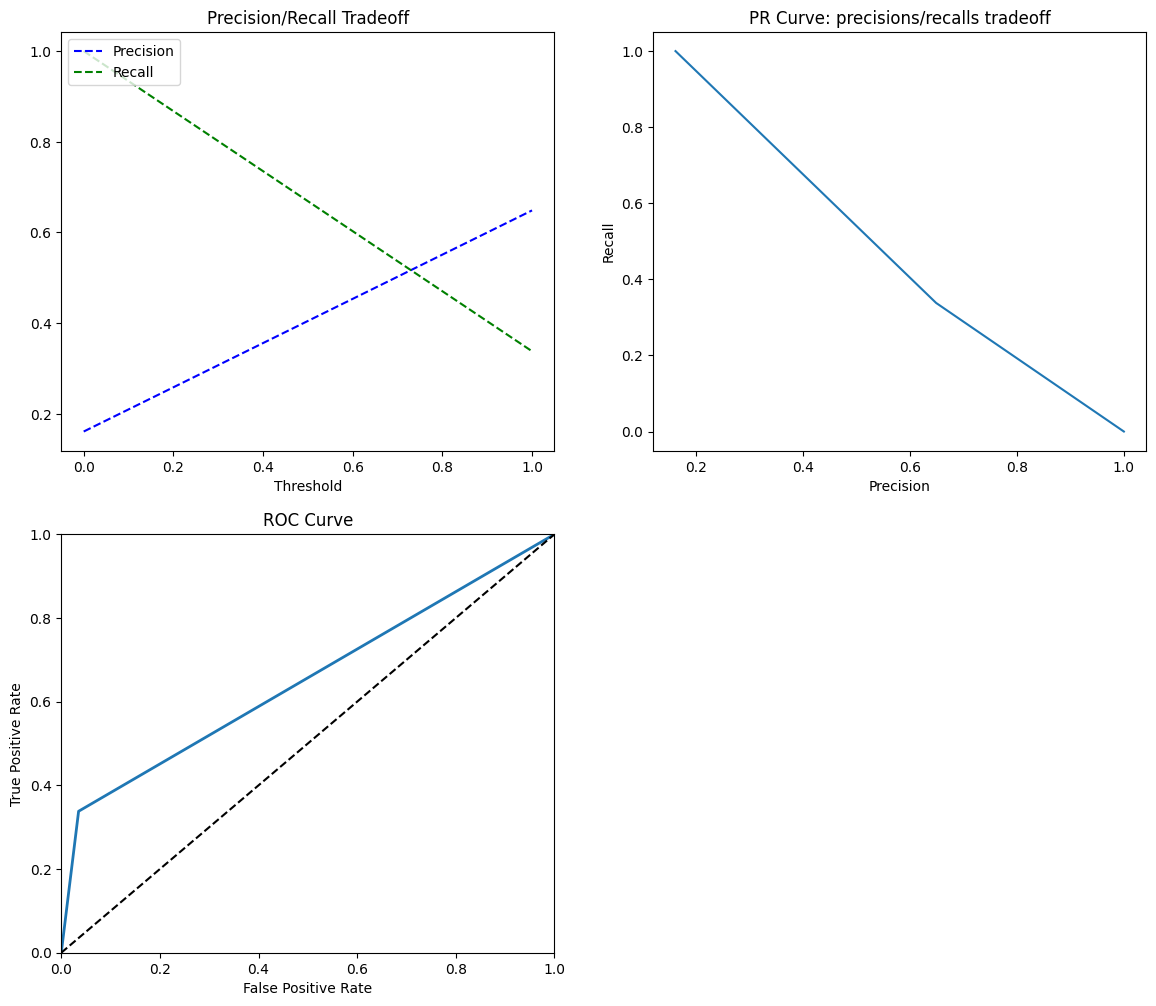

In [92]:
precisions, recalls, thresholds = precision_recall_curve(y_test, svm_clf.predict(X_test_std))
plt.figure(figsize=(14, 25))
plt.subplot(4, 2, 1)
plot_precision_recall_vs_threshold(precisions, recalls, thresholds)

plt.subplot(4, 2, 2)
plt.plot(precisions, recalls)
plt.xlabel("Precision")
plt.ylabel("Recall")
plt.title("PR Curve: precisions/recalls tradeoff");

plt.subplot(4, 2, 3)
fpr, tpr, thresholds = roc_curve(y_test, svm_clf.predict(X_test_std))
plot_roc_curve(fpr, tpr)

In [94]:
scores_dict['Support Vector Machine'] = {
        'Train': roc_auc_score(y_train, svm_clf.predict(X_train_std)),
        'Test': roc_auc_score(y_test, svm_clf.predict(X_test_std)),
    }
scores_dict['Support Vector Machine']

{'Train': 1.0, 'Test': 0.6514465169394748}

##### **✔️ XGBoost Classifier**

In [95]:
from xgboost import XGBClassifier

xgb_clf = XGBClassifier()
xgb_clf.fit(X_train, y_train)

evaluate(xgb_clf, X_train, X_test, y_train, y_test)

Training Result: -------------------------------
1. confusion_matrix:
[[863   0]
 [  0 166]]
2. accuracy_acore: 100.00 %
3. classification_report:
               0      1  accuracy  macro avg  weighted avg
precision    1.0    1.0       1.0        1.0           1.0
recall       1.0    1.0       1.0        1.0           1.0
f1-score     1.0    1.0       1.0        1.0           1.0
support    863.0  166.0       1.0     1029.0        1029.0

Testing Result: -------------------------------
1. confusion_matrix:
[[358  12]
 [ 52  19]]
2. accuracy_acore: 85.49 %
3. classification_report:
                    0          1  accuracy   macro avg  weighted avg
precision    0.873171   0.612903  0.854875    0.743037      0.831268
recall       0.967568   0.267606  0.854875    0.617587      0.854875
f1-score     0.917949   0.372549  0.854875    0.645249      0.830141
support    370.000000  71.000000  0.854875  441.000000    441.000000


In [96]:
scores_dict['XGBoost'] = {
        'Train': roc_auc_score(y_train, xgb_clf.predict(X_train)),
        'Test': roc_auc_score(y_test, xgb_clf.predict(X_test)),
    }

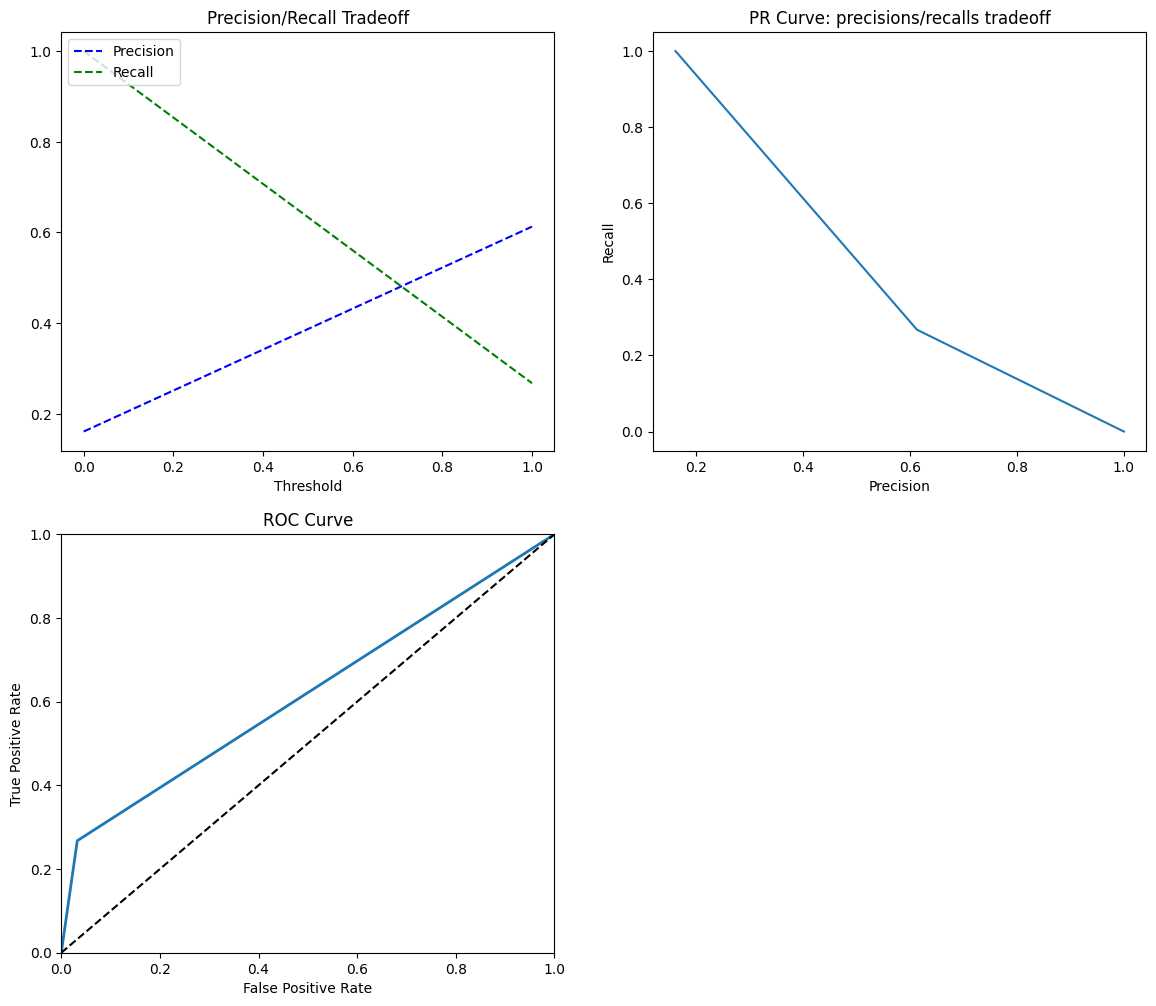

In [97]:
precisions, recalls, thresholds = precision_recall_curve(y_test, xgb_clf.predict(X_test))
plt.figure(figsize=(14, 25))
plt.subplot(4, 2, 1)
plot_precision_recall_vs_threshold(precisions, recalls, thresholds)

plt.subplot(4, 2, 2)
plt.plot(precisions, recalls)
plt.xlabel("Precision")
plt.ylabel("Recall")
plt.title("PR Curve: precisions/recalls tradeoff");

plt.subplot(4, 2, 3)
fpr, tpr, thresholds = roc_curve(y_test, xgb_clf.predict(X_test))
plot_roc_curve(fpr, tpr)


Text(0.5, 1.0, 'Feature Importance according to XGBoost')

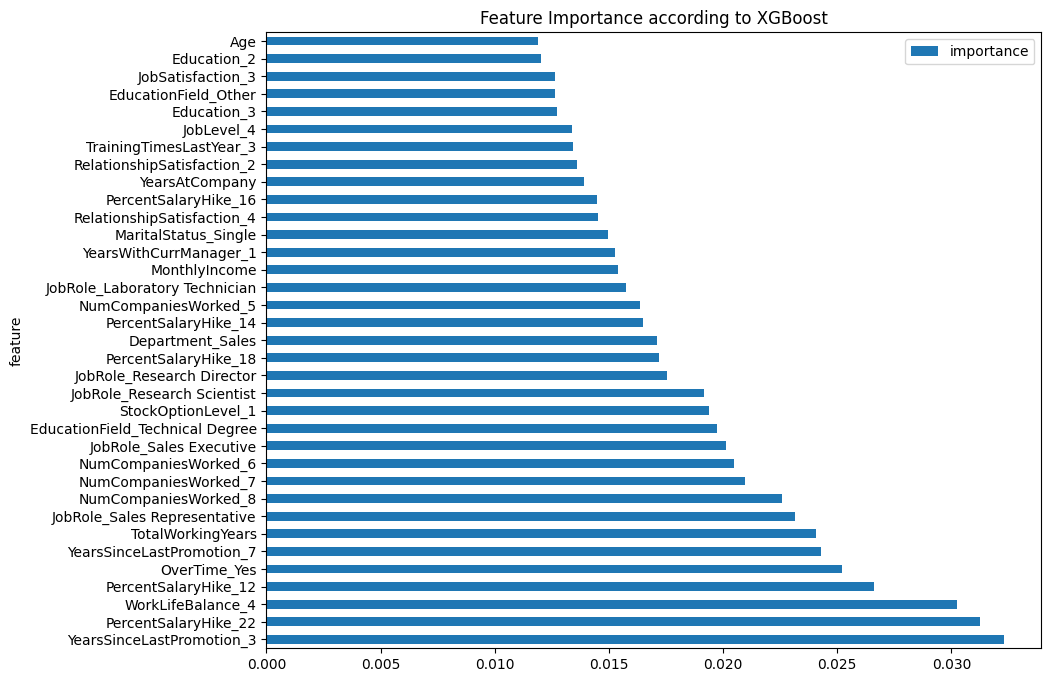

In [98]:
df = feature_imp(X, xgb_clf)[:35]
df.set_index('feature', inplace=True)
df.plot(kind='barh', figsize=(10, 8))
plt.title('Feature Importance according to XGBoost')

##### **✔️ LightGBM**

In [132]:
from lightgbm import LGBMClassifier

lgb_clf = LGBMClassifier(verbosity=-1, random_state=42)
lgb_clf.fit(X_train, y_train)

evaluate(lgb_clf, X_train, X_test, y_train, y_test)

Training Result: -------------------------------
1. confusion_matrix:
[[863   0]
 [  0 166]]
2. accuracy_acore: 100.00 %
3. classification_report:
               0      1  accuracy  macro avg  weighted avg
precision    1.0    1.0       1.0        1.0           1.0
recall       1.0    1.0       1.0        1.0           1.0
f1-score     1.0    1.0       1.0        1.0           1.0
support    863.0  166.0       1.0     1029.0        1029.0

Testing Result: -------------------------------
1. confusion_matrix:
[[358  12]
 [ 55  16]]
2. accuracy_acore: 84.81 %
3. classification_report:
                    0          1  accuracy   macro avg  weighted avg
precision    0.866828   0.571429  0.848073    0.719128      0.819269
recall       0.967568   0.225352  0.848073    0.596460      0.848073
f1-score     0.914432   0.323232  0.848073    0.618832      0.819250
support    370.000000  71.000000  0.848073  441.000000    441.000000


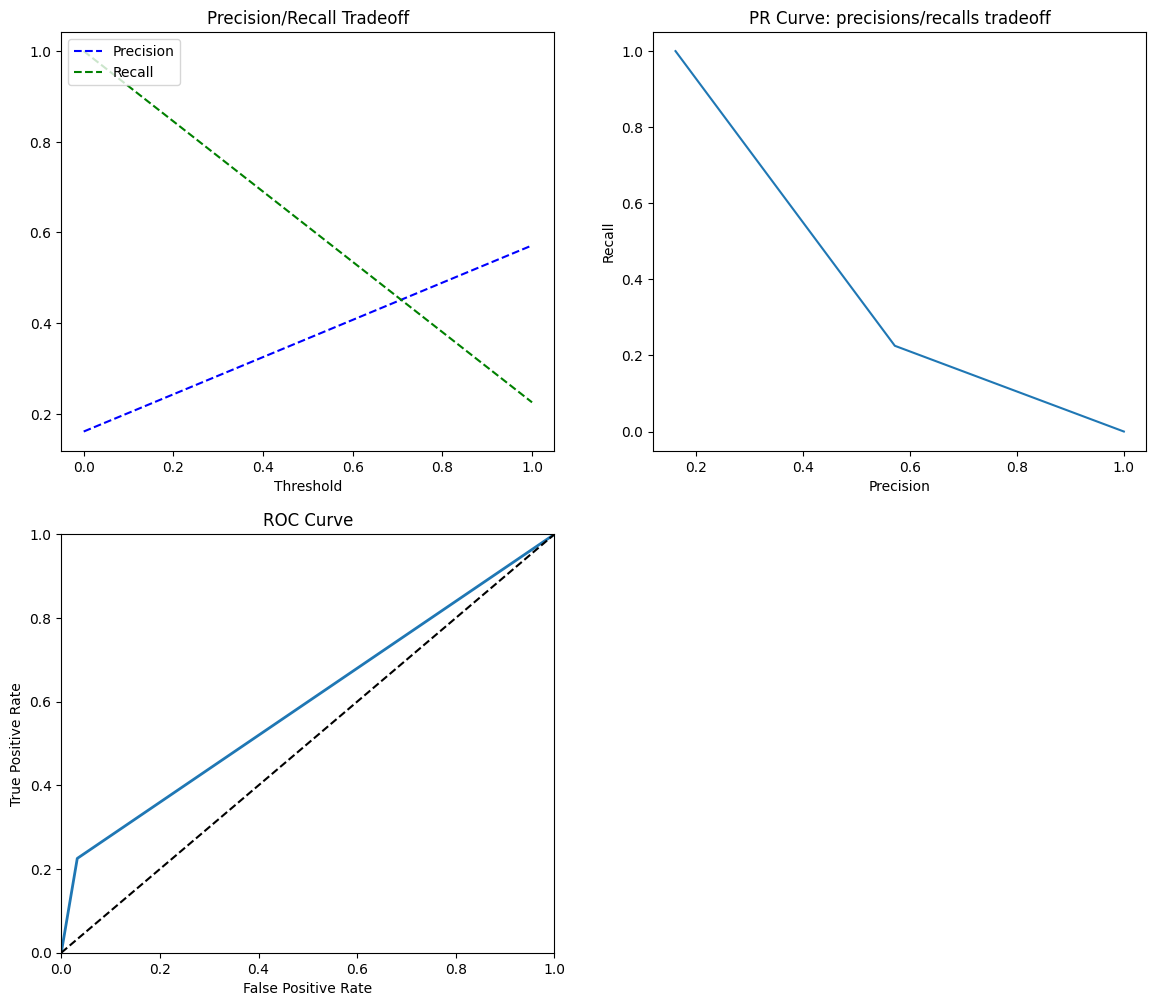

In [133]:
precisions, recalls, thresholds = precision_recall_curve(y_test, lgb_clf.predict(X_test))
plt.figure(figsize=(14, 25))
plt.subplot(4, 2, 1)
plot_precision_recall_vs_threshold(precisions, recalls, thresholds)

plt.subplot(4, 2, 2)
plt.plot(precisions, recalls)
plt.xlabel("Precision")
plt.ylabel("Recall")
plt.title("PR Curve: precisions/recalls tradeoff");

plt.subplot(4, 2, 3)
fpr, tpr, thresholds = roc_curve(y_test, lgb_clf.predict(X_test))
plot_roc_curve(fpr, tpr)


In [134]:
scores_dict['LightGBM'] = {
        'Train': roc_auc_score(y_train, lgb_clf.predict(X_train)),
        'Test': roc_auc_score(y_test, lgb_clf.predict(X_test)),
    }
scores_dict['LightGBM']

{'Train': 1.0, 'Test': 0.5964598401218119}

##### **✔️ CatBoost**

In [111]:
from catboost import CatBoostClassifier

cb_clf = CatBoostClassifier()
cb_clf.fit(X_train, y_train, verbose=0)

evaluate(cb_clf, X_train, X_test, y_train, y_test)

Training Result: -------------------------------
1. confusion_matrix:
[[863   0]
 [ 16 150]]
2. accuracy_acore: 98.45 %
3. classification_report:
                    0           1  accuracy    macro avg  weighted avg
precision    0.981797    1.000000  0.984451     0.990899      0.984734
recall       1.000000    0.903614  0.984451     0.951807      0.984451
f1-score     0.990815    0.949367  0.984451     0.970091      0.984129
support    863.000000  166.000000  0.984451  1029.000000   1029.000000

Testing Result: -------------------------------
1. confusion_matrix:
[[361   9]
 [ 58  13]]
2. accuracy_acore: 84.81 %
3. classification_report:
                    0          1  accuracy   macro avg  weighted avg
precision    0.861575   0.590909  0.848073    0.726242      0.817999
recall       0.975676   0.183099  0.848073    0.579387      0.848073
f1-score     0.915082   0.279570  0.848073    0.597326      0.812766
support    370.000000  71.000000  0.848073  441.000000    441.000000


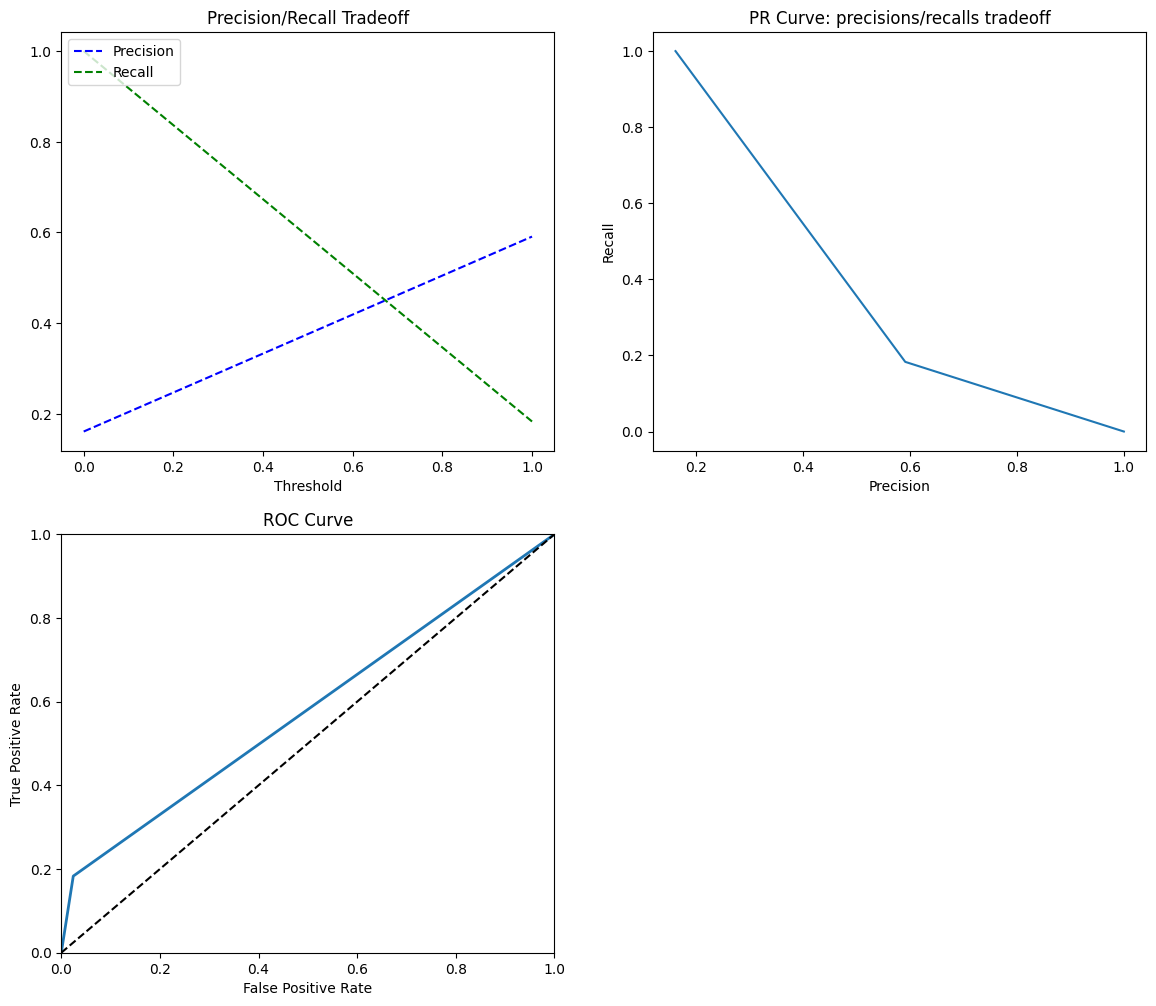

In [112]:
precisions, recalls, thresholds = precision_recall_curve(y_test, cb_clf.predict(X_test))
plt.figure(figsize=(14, 25))
plt.subplot(4, 2, 1)
plot_precision_recall_vs_threshold(precisions, recalls, thresholds)

plt.subplot(4, 2, 2)
plt.plot(precisions, recalls)
plt.xlabel("Precision")
plt.ylabel("Recall")
plt.title("PR Curve: precisions/recalls tradeoff");

plt.subplot(4, 2, 3)
fpr, tpr, thresholds = roc_curve(y_test, cb_clf.predict(X_test))
plot_roc_curve(fpr, tpr)


In [113]:
scores_dict['CatBoost'] = {
        'Train': roc_auc_score(y_train, cb_clf.predict(X_train)),
        'Test': roc_auc_score(y_test, cb_clf.predict(X_test)),
    }

##### **✔️ AdaBoost**

In [114]:
from sklearn.ensemble import AdaBoostClassifier

ab_clf = AdaBoostClassifier()
ab_clf.fit(X_train, y_train)

evaluate(ab_clf, X_train, X_test, y_train, y_test)

Training Result: -------------------------------
1. confusion_matrix:
[[856   7]
 [110  56]]
2. accuracy_acore: 88.63 %
3. classification_report:
                    0           1  accuracy    macro avg  weighted avg
precision    0.886128    0.888889  0.886297     0.887509      0.886574
recall       0.991889    0.337349  0.886297     0.664619      0.886297
f1-score     0.936031    0.489083  0.886297     0.712557      0.863928
support    863.000000  166.000000  0.886297  1029.000000   1029.000000

Testing Result: -------------------------------
1. confusion_matrix:
[[351  19]
 [ 57  14]]
2. accuracy_acore: 82.77 %
3. classification_report:
                    0          1  accuracy   macro avg  weighted avg
precision    0.860294   0.424242  0.827664    0.642268      0.790091
recall       0.948649   0.197183  0.827664    0.572916      0.827664
f1-score     0.902314   0.269231  0.827664    0.585772      0.800389
support    370.000000  71.000000  0.827664  441.000000    441.000000


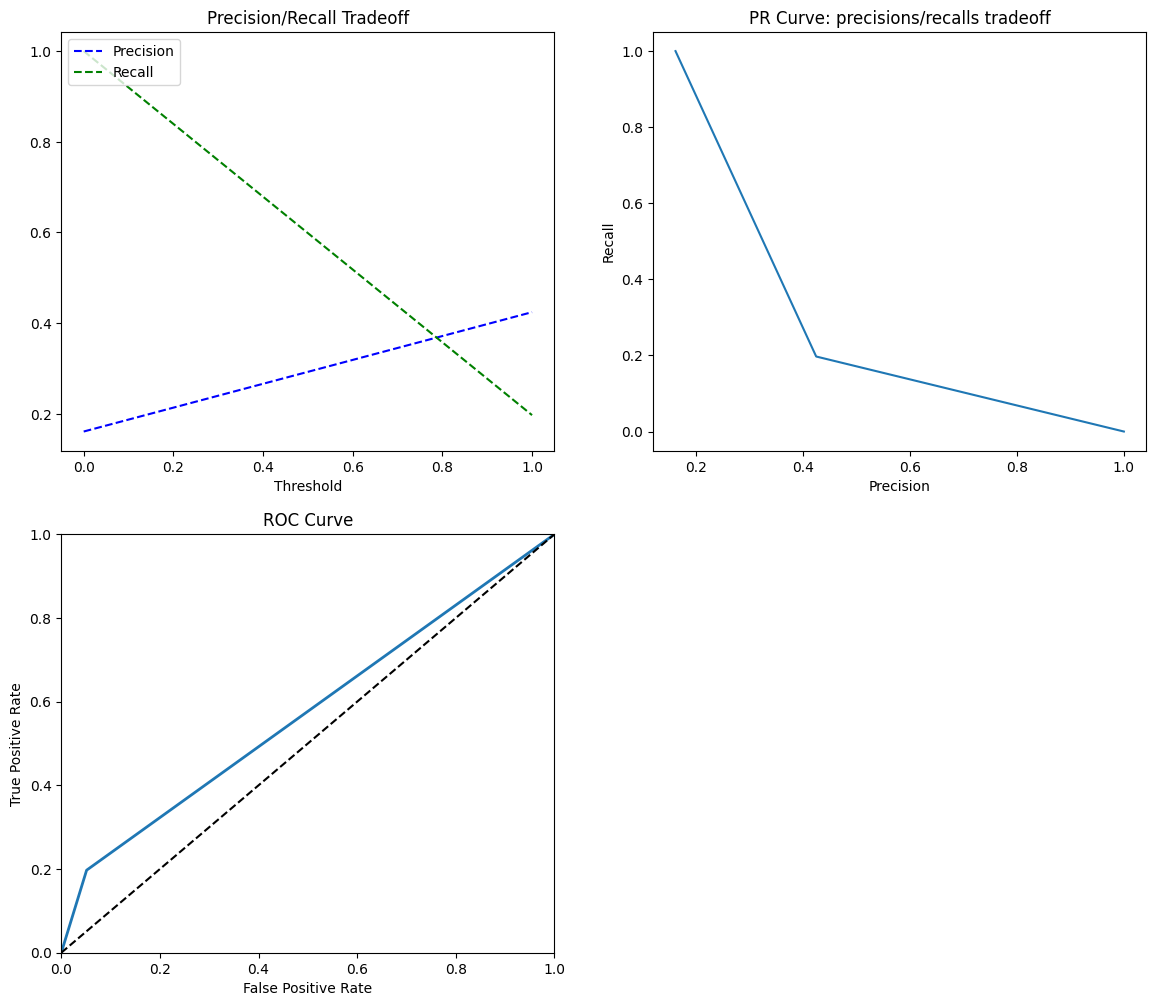

In [115]:
precisions, recalls, thresholds = precision_recall_curve(y_test, ab_clf.predict(X_test))
plt.figure(figsize=(14, 25))
plt.subplot(4, 2, 1)
plot_precision_recall_vs_threshold(precisions, recalls, thresholds)

plt.subplot(4, 2, 2)
plt.plot(precisions, recalls)
plt.xlabel("Precision")
plt.ylabel("Recall")
plt.title("PR Curve: precisions/recalls tradeoff");

plt.subplot(4, 2, 3)
fpr, tpr, thresholds = roc_curve(y_test, ab_clf.predict(X_test))
plot_roc_curve(fpr, tpr)


In [116]:
scores_dict['AdaBoost'] = {
        'Train': roc_auc_score(y_train, ab_clf.predict(X_train)),
        'Test': roc_auc_score(y_test, ab_clf.predict(X_test)),
    }

#### **🎯 Comparing Models Prerformance 📊**

In [135]:
ml_models = {
    'Random Forest': rf_clf, 
    'XGBoost': xgb_clf, 
    'Logistic Regression': lr_clf,
    'Support Vector Machine': svm_clf,
    'LightGBM': lgb_clf,
    'CatBoost': cb_clf,
    'AdaBoost': ab_clf
}

for model in ml_models:
    print(f"{model.upper():{30}} roc_auc_score: {roc_auc_score(y_test, ml_models[model].predict(X_test)):.3f}")


RANDOM FOREST                  roc_auc_score: 0.535
XGBOOST                        roc_auc_score: 0.518
LOGISTIC REGRESSION            roc_auc_score: 0.537
SUPPORT VECTOR MACHINE         roc_auc_score: 0.500
LIGHTGBM                       roc_auc_score: 0.596
CATBOOST                       roc_auc_score: 0.500
ADABOOST                       roc_auc_score: 0.500


c:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
c:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
c:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but AdaBoostClassifier was fitted without feature names
  warnings.warn(


<Axes: >

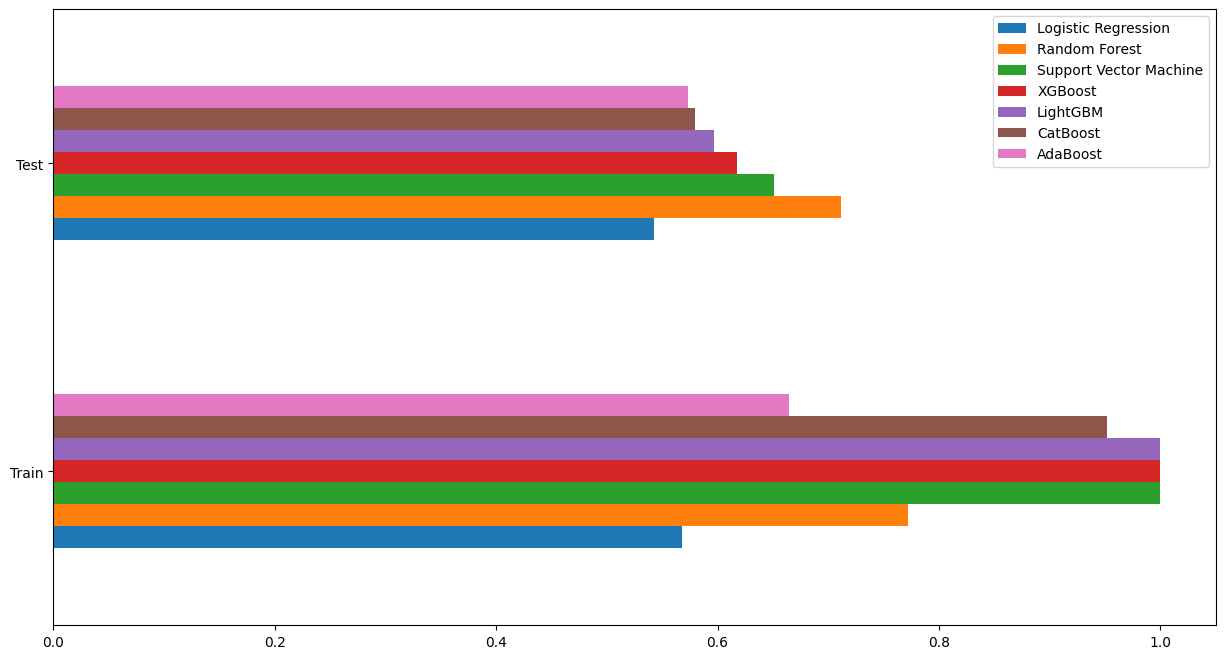

In [139]:
scores_df = pd.DataFrame(scores_dict)
scores_df.plot(kind='barh', figsize=(15, 8))
